# Предобработка данных по заказу "Карта ДТП" #

Заказчик проекта — «Карта ДТП». Это некоммерческий проект, посвящённый проблеме дорожно-транспортных происшествий в России. "Карта ДТП" работает для повышения безопасности на дорогах.

«Карта ДТП» помогает выявлять реальные причины ДТП, оценивать уровень развития инфраструктуры, а также разрабатывать качественные решения и программы по повышению безопасности на улицах и дорогах. Заказчик хочет собирать данные более высокого качества и ожидает рекомендаций: на какие проблемы или особенности обратить внимание.

**Цель работы** - подготовить данные для заказчика. Поставлены следующие **задачи**:
- провести загрузку данных
- выполнить действия по предобработке данных: обработать названия колонок, типы, провести работу с пропусками и дубликатами, объеденить датасеты
- представить ответы на вопросы заказчика: как менялось число ДТП по временным промежуткам, различается ли число ДТП для групп водителей с разным стажем.

## Описание данных

Данные `Kirovskaya_oblast.csv`, `Moscowskaya_oblast.csv` содержат информацию ДТП:

* `geometry.coordinates` — координаты ДТП;

* `id` — идентификатор ДТП;

*  `properties.tags` — тег происшествия;

*  `properties.light` — освещённость;

*  `properties.point.lat` — широта;

*  `properties.point.long` — долгота;

*  `properties.nearby` — ближайшие объекты;

*  `properties.region` — регион;

*  `properties.scheme` — схема ДТП;

*  `properties.address` — ближайший адрес;

*  `properties.weather` — погода;

*  `properties.category` — категория ДТП;

*  `properties.datetime` — дата и время ДТП;

*  `properties.injured_count` — число пострадавших;

*  `properties.parent_region` — область;

*  `properties.road_conditions` — состояние покрытия;

*  `properties.participants_count` — число участников;

*  `properties.participant_categories` — категории участников.

`Moscowskaya_oblast_participiants.csv`, `Kirovskaya_oblast_participiants.csv` — сведения об участниках ДТП:

* `role` — роль;

* `gender` — пол;

* `violations` — какие правила дорожного движения были нарушены конкретным участником;

* `health_status` — состояние здоровья после  ДТП;

* `years_of_driving_experience` — число лет опыта;

* `id` — идентификатор ДТП.


`Kirovskaya_oblast_vehicles.csv`, `Moscowskaya_oblast_vehicles.csv` — сведения о транспортных средствах:

* `year` — год выпуска;

* `brand` — марка транспортного средства;

* `color` — цвет;

* `model` — модель;

* `category` — категория;

* `id` — идентификатор ДТП.

### Содежание ###

1. Загрузка данных:
 - Знакомство с данными: вывод их на экран, проверка соответствия описанию
 - Выработка плана действий на этапе предобработки
2. Предобработка данных
 - Корректировка типов данных
 - Объединение датасетов
 - Работа с пропусками
 - Проверка правильности категориальных данных
 - Проверка корректности количественных данных
 - Работа с дубликатами
3. Исследовательский анализ данных
 - Количество ДТП по дням недели и количество ДТП по месяцам
 - Анализ ДТП в разрезе стажа водителей
 - Анализ количества ДТП по Кировской и Московской областям по годам
4. Выводы

## 1. Загрузка данных ##

### 1.1. Знакомство с данными

In [1]:
# Импортируем бибилиотеке, необходимые для работы с данными
import pandas as pd
import ast
from geopy.geocoders import Nominatim
import math
import matplotlib.pyplot as plt

In [2]:
# Загружаем данные как датафреймы в переменные
df_mo = pd.read_csv('Moscowskaya_oblast.csv') # Данные по ДТП в Московской области
df_ko = pd.read_csv('Kirovskaya_oblast.csv') # Данные по ДТП в Кироской области
df_mo_part = pd.read_csv('Moscowskaya_oblast_participiants.csv') # Данные по участникам из Московской области
df_ko_part = pd.read_csv('Kirovskaya_oblast_participiants.csv') # Участники по Кировской области
df_mo_vech = pd.read_csv('Moscowskaya_oblast_vehicles.csv') # Транспорные средства по Московской области
df_ko_vech = pd.read_csv('Kirovskaya_oblast_vehicles.csv') # Траснспортные средства по Кироской области

In [3]:
# Проверим данные по ДТП в Московской и Кировской областях
display(df_mo[-5:], df_ko[-5:])

,geometry.coordinates,id,properties.tags,properties.light,properties.point.lat,properties.point.long,properties.nearby,properties.region,properties.scheme,properties.address,properties.weather,properties.category,properties.datetime,properties.injured_count,properties.parent_region,properties.road_conditions,properties.participants_count,properties.participant_categories
45613,"[36.3492, 55.5653]",2143184,['Дорожно-транспортные происшествия'],Светлое время суток,55.565300,36.34920,[],Рузский,900.0,"СТ.НИКОЛАЕВО-ЛЫЩИКОВО-ДОРОХОВО, 8 км",['Ясно'],Иной вид ДТП,2017-05-28 12:30:00,1,Московская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,['Все участники']
45614,"[38.2545, 55.5245]",2162452,"['Дорожно-транспортные происшествия', 'ДТП и п...","В темное время суток, освещение включено",55.524500,38.25450,"['Многоквартирные жилые дома', 'Производственн...",Ногинский,740.0,"г Ногинск, ул Декабристов, 79А","['Пасмурно', 'Дождь']",Наезд на пешехода,2017-12-10 20:30:00,1,Московская область,['Мокрое'],2,"['Все участники', 'Пешеходы', 'Дети']"
45615,"[38.04515, 55.978343]",2156704,['Дорожно-транспортные происшествия'],Светлое время суток,55.978343,38.04515,"['Остановка общественного транспорта', 'Нерегу...",Фрязино,210.0,"г Фрязино, МИХАЙЛОВКА-ЛУКЬЯНОВО, 0 км",['Ясно'],Столкновение,2019-05-26 19:55:00,2,Московская область,"['Сухое', 'Отсутствие, плохая различимость гор...",3,['Все участники']
45616,"[39.1436, 55.7061]",2143503,['Дорожно-транспортные происшествия'],Светлое время суток,55.706100,39.14360,[],Орехово-Зуевский,70.0,"ЛИКИНО-ДУЛЕВО-ШАТУРА-ШАТУРТОРФ, 13 км",['Ясно'],Столкновение,2017-05-20 15:00:00,1,Московская область,['Сухое'],2,['Все участники']
45617,"[36.39136, 55.35632]",2130572,['Дорожно-транспортные происшествия'],"В темное время суток, освещение отсутствует",55.356320,36.39136,[],Наро-Фоминский,200.0,"МБК-ВОЛЧЕНКИ, 3 км",['Дождь'],Столкновение,2016-04-02 20:20:00,3,Московская область,"['Мокрое', 'Отсутствие, плохая различимость го...",4,['Все участники']


,geometry.coordinates,id,properties.tags,properties.light,properties.point.lat,properties.point.long,properties.nearby,properties.region,properties.scheme,properties.address,properties.weather,properties.category,properties.datetime,properties.injured_count,properties.parent_region,properties.road_conditions,properties.participants_count,properties.participant_categories
14512,"[51.090943, 56.233566]",1981076,Дорожно-транспортные происшествия,Светлое время суток,56.233566,51.090943,['Жилые дома индивидуальной застройки'],Вятско-Полянский район,NaN,"г Вятские Поляны, ул Набережная, 6",['Ясно'],Иной вид ДТП,2018-05-17 06:20:00,1,Кировская область,['Сухое'],1,"['Все участники', 'Мотоциклисты']"
14513,"[50.8911, 56.1978]",1985930,Дорожно-транспортные происшествия,Сумерки,56.197800,50.891100,[],Вятско-Полянский район,330.0,NaN,['Ясно'],Столкновение,2019-05-30 18:35:00,1,Кировская область,['Сухое'],2,"['Все участники', 'Дети']"
14514,"[51.079817, 56.22997]",1985949,Дорожно-транспортные происшествия,Светлое время суток,56.229970,51.079817,"['Многоквартирные жилые дома', 'Выезд с прилег...",Вятско-Полянский район,NaN,"г Вятские Поляны, ул Урицкого, 20",['Ясно'],Столкновение,2019-05-13 09:20:00,1,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,['Все участники']
14515,"[51.165556, 56.152222]",1986807,Дорожно-транспортные происшествия,Светлое время суток,56.152222,51.165556,"['Многоквартирные жилые дома', 'Жилые дома инд...",Вятско-Полянский район,500.0,"г Сосновка, ул Пролетарская, 13",['Ясно'],Столкновение,2015-08-12 17:05:00,3,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",3,['Все участники']
14516,"[51.1217, 56.2153]",1987515,Дорожно-транспортные происшествия,Светлое время суток,56.215300,51.121700,['Выезд с прилегающей территории'],Вятско-Полянский район,130.0,"Вятские Поляны - Сосновка, 1 км",['Ясно'],Столкновение,2016-08-22 18:05:00,1,Кировская область,['Сухое'],2,['Все участники']


In [4]:
# Видедем на экран информацию по датасетам с ДТП
display('ДТП в Московской области', df_mo.info())
print()
display('ДТП в Кировской области', df_ko.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45618 entries, 0 to 45617
Data columns (total 18 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   geometry.coordinates               45618 non-null  object 
 1   id                                 45618 non-null  int64  
 2   properties.tags                    45618 non-null  object 
 3   properties.light                   45618 non-null  object 
 4   properties.point.lat               45615 non-null  float64
 5   properties.point.long              45615 non-null  float64
 6   properties.nearby                  45618 non-null  object 
 7   properties.region                  45618 non-null  object 
 8   properties.scheme                  44235 non-null  float64
 9   properties.address                 43862 non-null  object 
 10  properties.weather                 45618 non-null  object 
 11  properties.category                45618 non-null  obj

'ДТП в Московской области'

None


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14517 entries, 0 to 14516
Data columns (total 18 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   geometry.coordinates               14517 non-null  object 
 1   id                                 14517 non-null  int64  
 2   properties.tags                    14517 non-null  object 
 3   properties.light                   14517 non-null  object 
 4   properties.point.lat               14485 non-null  float64
 5   properties.point.long              14485 non-null  float64
 6   properties.nearby                  14517 non-null  object 
 7   properties.region                  14517 non-null  object 
 8   properties.scheme                  13380 non-null  float64
 9   properties.address                 13843 non-null  object 
 10  properties.weather                 14517 non-null  object 
 11  properties.category                14517 non-null  ob

'ДТП в Кировской области'

None

Выявлено, что атрибуты полностью соответствуют представленному описанию.

Знакомство с данными позволио выявить следующие проблемы, решить которые предстоит на предобработке:
- В наименовании колонок используется имена схем (например -  `properties.`) следует исключить их для уменьшения количества строк кода и количества набираемых символов при анализе данных.
- Поле `geometry.coordinates` дублирует информацию из полей `properties.point.lat` и `properties.point.long` необходимо проверить дублирование информации в этих полях и оставить два поля с информацией и широте и долготе ДТП.
 - При этом в ряде строк по полям `properties.point.lat` и `properties.point.long` имеются пропуски, при этом поле `geometry.coordinates` заполнено для всех строк. Предлагается заполнить данные по широте и долготе ДТП на основании поля с координатами.
 - У поля `properties.datetime ` тип данных `object`, его следует изменить на `datetime`
 - У числовых полей `id`, `properties.injured_count`, `properties.participants_count` выбрана неоптимальная разрядность. На этапе предобработке следует ее понизить.
 - Для датасета с ДТП по Московской областью ячейки по полю `properties.tags` представлены в виде списка, в то время как в датасете по Кировской области ячейки представлены строкой. Следует проверить проверить, какие категории атрибута существуют, привести категории к единообразию и изменить тип данных на `category`.
 - Поле `properties.nearby` преставлено списками, будет осуществлна проверка уникальности категорий из списка (в одинакавом ли порядке записаны элементы списка). Данные необходимо привести к одинаковым категориям.
 - Такие же действия требуется осуществить по полям `properties.weather`, `properties.road_conditions`, `properties.participant_categories`, т.е. проверить перестановки элементов в списке и исключить их. Тип полей следует привети к типу `category`.
 - Поле `properties.region` следует привести к типу данных `category`.
 - Поле `properties.address` записано разным регистром для двух представленных датасетов. Данные необходимо нормализовать: привести к заглавному регистру.
 - `properties.parent_region` содержит информацию об области ДТП. Поле будет полезно при соединении датасетов в один (через конкатенацию), так как устанавливает категорию региона. Данные по полю в том случае, если они содержат только 2 категории: Московская или Кировская области следует привести к булеву типу.

In [5]:
# Вывод на экран пяти первых строк датасетов с информацией об участниках
display(df_mo_part.head(), df_ko_part.head())

,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,[],Не пострадал,13.0,2163589
1,Водитель,Мужской,[],Не пострадал,13.0,2163589
2,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
3,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
4,Водитель,Женский,[],Не пострадал,11.0,2163319


,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,['Несоответствие скорости конкретным условиям ...,"Раненый, находящийся (находившийся) на амбулат...",26.0,1983180
1,Водитель,Мужской,[],Не пострадал,34.0,2889433
2,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208
3,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208
4,Водитель,Мужской,[],Не пострадал,27.0,2577639


In [6]:
# Вывод информации по датасетам с участниками
display(df_mo_part.info(), df_ko_part.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95177 entries, 0 to 95176
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   role                         95177 non-null  object 
 1   gender                       93307 non-null  object 
 2   violations                   95177 non-null  object 
 3   health_status                95070 non-null  object 
 4   years_of_driving_experience  59679 non-null  float64
 5   id                           95177 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 4.4+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31235 entries, 0 to 31234
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   role                         31235 non-null  object 
 1   gender                       30387 non-null  object 
 2   violations           

None

None

Представленные данные по участникам ДТП соответствуют описанию.

Действия, которые необходимо выполнить на этапе предообработки
 - Поле `years_of_driving_experience` назвать покороче `driving_exp`. Тип данных изменить на целочисленный с понижением разрядности.
 - Посчитать количество категорий по полю `role`. Если их две - изменить тип данных на булев, если больше - на `category`.
 - Тип поля `gender` изменить на булев, пропуски оставить без изменений.
 - Проверить категориальные данные по полю `violations`. Перевести их в тип `category`.
 - Проверить категориальные данные по полю `health_status`. Перевести их в тип `category`.
 - Понизить рязрядность у поля `id`.

In [7]:
# Выведем первые сроки датасетов с информацией о транспортных средствах
display(df_mo_vech.head(), df_ko_vech.head())

,year,brand,color,model,category,id
0,2012.0,ГАЗ,Белый,Прочие модели ГАЗ,Фургоны,2163589
1,2008.0,OPEL,Черный,Astra,"С-класс (малый средний, компактный) до 4,3 м",2155398
2,2017.0,MAZDA,Черный,CX-5,"В-класс (малый) до 3,9 м",2163319
3,2013.0,ГАЗ,Белый,"2705 Газель , 27057 и модификации",Фургоны,2143938
4,2011.0,RENAULT,Синий,Прочие модели Renault,"В-класс (малый) до 3,9 м",2163390


,year,brand,color,model,category,id
0,2011.0,ВАЗ,Серый,Kalina,"А-класс (особо малый) до 3,5 м",1983180
1,2005.0,CHEVROLET,Зеленый,Niva,"С-класс (малый средний, компактный) до 4,3 м",2889433
2,2017.0,RENAULT,Синий,Logan,"С-класс (малый средний, компактный) до 4,3 м",2591208
3,2006.0,ВАЗ,Зеленый,ВАЗ 2115 и модификации,"С-класс (малый средний, компактный) до 4,3 м",2577639
4,1986.0,MERCEDES,Зеленый,Прочие модели Mercedes,Фургоны,1981026


In [8]:
# Сводка по датасетам с информацией о транспортных средствах.
display(df_mo_vech.info(), df_ko_vech.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65606 entries, 0 to 65605
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      63860 non-null  float64
 1   brand     64185 non-null  object 
 2   color     64765 non-null  object 
 3   model     64185 non-null  object 
 4   category  65606 non-null  object 
 5   id        65606 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 3.0+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20093 entries, 0 to 20092
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      19299 non-null  float64
 1   brand     19318 non-null  object 
 2   color     19643 non-null  object 
 3   model     19318 non-null  object 
 4   category  20093 non-null  object 
 5   id        20093 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 942.0+ KB


None

None

Данные соответствуют описанию.

Требуеются следующие действия по предобработке:
 - Тип поля `year` следует заменить на целочисленный с понижением разряднсти. Пропущенные значений года выпуска предлагается заполнить техническим значением.
 - Пропуски в полях `brand`, `color`, `model` следует заполнить техническим значением.
 - Провести нормализацию значений (при необходимости) по полям `brand`, `color`, `model`, `category`, тип данных заменить на `category`
 - Понизить разрядность поля `id`.

### 1.2. План действий на этапе предобработки

Размер каждого из представленных датасетов не превышает 10 Мб: ресурсов системы достаточно для объеденения их в один датасет и дальнейшей работы с ним.

Предлагается осущевтвить следующую последоваельность действий.
1. Проверить необходимость преобрабования значений поля `properties.tags` к списку. Привести это поле к одному виду для датафреймов с информацией о ДТП по Московской области и Кировской области.
2. Проверить то, что атрибут `properties.parent_region` в датасетах с инофрмаций о ДТП содержит значение Московская область для первого датасета и Кировская область - для второго датасета.
3. Выполнить конкатенацию датасетов с информацией о ДТП (добавить строки одного к другому)
4. Проверить соответствие первичного ключа `id` датасетов с информацией о ДТП с внешними ключами прочих датасетов (выявить обо всех ли зарегестрированных ДТП есть информация в прочих таблицах.
5. Провести предобработку данных в объединенном датасете с информацией по ДТП: отредактировать названия колонок, изменить типы данных, обработать пропуски, проверить категориальные и количественные типы данных, обработать дубликаты.
6. Провести предобработку датасетов с информацией об участниках ДТП: объединить датасеты, изменить типы данных, обработать пропуски, проверить категориальные и количественные типы данных, обработать дубликаты
7. Провести предобработку датасетов с информацией о транспортрых средствах: объединить датасеты, откорректировать типы данных, обработать пропуски, проверить корректность данных, исключить дубликаты.
8. Составить описание действий, выполненных на этапе предобработки данных.

Итогом работы должны стать 3 датасета: с информацией о ДТП, с информацией об участниках и с информацией о транспортрых средствах. Для дальнейшего анализа можно будет объединять эти датасеты при необходимости.

## 2. Предобработка данных

### 2.1. Приведение к единообразию колонки с тегами

In [9]:
# Проверка содержания по полю properties.tags
df_mo['properties.tags'].value_counts()

properties.tags
['Дорожно-транспортные происшествия']                                                                                                                                                          41542
['Дорожно-транспортные происшествия', 'ДТП и пострадавшие дети в возрасте до 16 лет']                                                                                                           3678
['Дорожно-транспортные происшествия', 'ДТП и пострадавшие пешеходы, из-за наезда на пешеходов, на пешеходных переходах, по вине пешеходов']                                                      342
['Дорожно-транспортные происшествия', 'ДТП и пострадавшие пешеходы, из-за наезда на пешеходов, на пешеходных переходах, по вине пешеходов', 'ДТП и пострадавшие дети в возрасте до 16 лет']       56
Name: count, dtype: int64

Коомбинации тегов ДТП по Московской области уникальны, а информация представлена в виде списка, пропущеных значений нет. Сочетаний с престановками не обнаружено. Данные можно использовать в том виде, в котором они представлены.

In [10]:
df_ko['properties.tags'].value_counts()

properties.tags
Дорожно-транспортные происшествия    14517
Name: count, dtype: int64

Есть проблема с тегами по Кировской области - он всего 1 и общий для всех. Для приведения данных к единообразию, преобразуем этом тег в список, состоящий из одного элемента для всех строк. В дальнейшем получить конкретных тег из списка можно через следующий код.

In [11]:
# Пример кода для получений отдельного тега из списка тегов.
tag = df_mo.iloc[1]['properties.tags']
tag = ast.literal_eval(tag)
tag[0]

'Дорожно-транспортные происшествия'

In [12]:
# Заменяем значения в датасете с ДТП по Кировской области на спископодобную форму
df_ko['properties.tags'] = df_ko['properties.tags'].str.replace('Дорожно-транспортные происшествия', "['Дорожно-транспортные происшествия']")

### 2.2. Проверка атрибута `properties.parent_region` для каждого датасета

In [13]:
# Московская область
df_mo['properties.parent_region'].unique()

array(['Московская область'], dtype=object)

In [14]:
# Проверка наличия пропусков в наименовавнии региона
df_mo['properties.parent_region'].isna().sum()

np.int64(0)

In [15]:
# Кироская область
df_ko['properties.parent_region'].unique()

array(['Кировская область'], dtype=object)

In [16]:
# Проверка наличия пропусков
df_ko['properties.parent_region'].isna().sum()

np.int64(0)

В двух датасетах по ДТП колонка предствлена одинм уникальным значением для каждого датасета, при этом пропусков в этой колонке не содержится. Можно выполнить конкатенацию датасетев, а в дальнейшем заменить тип колоки на булев, так как имеем информацию только по 2 регионам.

### 2.3. Конкатенация датасетов с иформацией по ДТП

In [17]:
df = pd.concat([df_mo, df_ko], axis=0) # Склеиваем датасеты

In [18]:
# Выводим несколько строк объединенного датасета и информацию по нему
display(df.sample(5), df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 60135 entries, 0 to 14516
Data columns (total 18 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   geometry.coordinates               60135 non-null  object 
 1   id                                 60135 non-null  int64  
 2   properties.tags                    60135 non-null  object 
 3   properties.light                   60135 non-null  object 
 4   properties.point.lat               60100 non-null  float64
 5   properties.point.long              60100 non-null  float64
 6   properties.nearby                  60135 non-null  object 
 7   properties.region                  60135 non-null  object 
 8   properties.scheme                  57615 non-null  float64
 9   properties.address                 57705 non-null  object 
 10  properties.weather                 60135 non-null  object 
 11  properties.category                60135 non-null  object 


,geometry.coordinates,id,properties.tags,properties.light,properties.point.lat,properties.point.long,properties.nearby,properties.region,properties.scheme,properties.address,properties.weather,properties.category,properties.datetime,properties.injured_count,properties.parent_region,properties.road_conditions,properties.participants_count,properties.participant_categories
38905,"[36.857843, 55.616025]",2144866,['Дорожно-транспортные происшествия'],Светлое время суток,55.616025,36.857843,"['Многоквартирные жилые дома', 'Выезд с прилег...",Одинцовский,140.0,"п Часцы, МОСКВА-БОРОДИНО, 53 км",['Пасмурно'],Столкновение,2018-11-23 14:03:00,2,Московская область,['Сухое'],3,['Все участники']
13167,"[38.035011, 55.723267]",2964433,['Дорожно-транспортные происшествия'],Светлое время суток,55.723267,38.035011,[],Железнодорожный,960.0,"г Железнодорожный, ул Центральная, 12",['Пасмурно'],Падение пассажира,2024-04-28 11:25:00,1,Московская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,['Все участники']
15562,"[37.5897, 55.5189]",2134327,['Дорожно-транспортные происшествия'],"В темное время суток, освещение отсутствует",55.518900,37.589700,"['Остановка общественного транспорта', 'Нерегу...",Ленинский,750.0,NaN,['Дождь'],Наезд на пешехода,2017-10-04 19:30:00,1,Московская область,"['Мокрое', 'Недостаточное освещение', 'Отсутст...",2,"['Все участники', 'Пешеходы']"
5341,"[49.72837, 58.64454]",2741714,['Дорожно-транспортные происшествия'],Светлое время суток,58.644540,49.728370,"['Выезд с прилегающей территории', 'Нерегулиру...",Киров,420.0,"г Киров, ул Семашко, 2",['Ясно'],Столкновение,2022-08-12 13:30:00,1,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,"['Все участники', 'Мотоциклисты']"
13493,"[38.107356, 55.608318]",2144111,"['Дорожно-транспортные происшествия', 'ДТП и п...",Светлое время суток,55.608318,38.107356,"['Многоквартирные жилые дома', 'Нерегулируемый...",Жуковский,700.0,"г Жуковский, ул Мичурина, 18",['Пасмурно'],Наезд на пешехода,2018-12-18 16:05:00,1,Московская область,['Обработанное противогололедными материалами'...,2,"['Все участники', 'Пешеходы', 'Дети']"


None

In [19]:
# Проверим, все ли строки содержатся в объединеном датасете
result = df.shape[0] - df_mo.shape[0] - df_ko.shape[0]
if result == 0:
    print('Количество строк в объединенном датасете совпадает с количеством строк в объединяемых датасетах')
else:
    print('При объединение датасетов произошла ошибка')

Количество строк в объединенном датасете совпадает с количеством строк в объединяемых датасетах


### 2.4. Проверка ключа `id`

In [20]:
# Функция для проверки ключа id
def check_id(dataframe):
    num_unique = dataframe['id'].nunique() # Подсчет количества уникальных идентификаторов
    print(f"Общее кол-во уникальных id ДТП - {num_unique}")
    if num_unique == dataframe.shape[0]:
        print("Идентификатор ДТП уникален для каждой строчки датасета")
    else:
        print("Идентификаторы не уникальны")

In [21]:
check_id(df)

Общее кол-во уникальных id ДТП - 60135
Идентификатор ДТП уникален для каждой строчки датасета


In [22]:
check_id(df_mo_part)

Общее кол-во уникальных id ДТП - 38833
Идентификаторы не уникальны


In [23]:
check_id(df_ko_part)

Общее кол-во уникальных id ДТП - 13340
Идентификаторы не уникальны


In [24]:
check_id(df_mo_vech)

Общее кол-во уникальных id ДТП - 38614
Идентификаторы не уникальны


In [25]:
check_id(df_ko_vech)

Общее кол-во уникальных id ДТП - 13247
Идентификаторы не уникальны


Идентификаторы событий уникальны только для датасета с инофрмацией о ДТП. Для прочих датасетов индентификтор ДТП не является уникальным значением: в дном ДТП могло быть несколько участников или транспортрых средств. Более того, по части ДТП нет информации о транспортных средствах, участниках.

In [26]:
# Найдем ДТП без информации об участниках
no_part_ids = set(df['id']) - set(df_mo_part['id']) - set(df_ko_part['id'])
no_part_ids = list(no_part_ids)
len(no_part_ids)

7962

In [27]:
# Найдем ДТП без информации о транспортных средствах
no_vech_ids = set(df['id']) - set(df_mo_vech['id']) - set(df_ko_vech['id'])
no_vech_ids = list(no_vech_ids)
len(no_vech_ids)

8274

Следует ометить для для весомой части ДТП отсутствует иноформация об участниках и(или) транспортных средствах. Объединение датасетов по условию присутствия индентификаторов в обоих из них будет вести к потери части записей по ДТП. Поэтому в рамках данной работы датасеты не будут собраны в один общий.

### 2.5. Предобоработка данных в датасете с информацией по ДТП

In [28]:
# Сохраняем информацию о объеме датасета до предобработки
df_shape_start = df.shape
print(f"Датасет до предобработки содержит {df_shape_start[0]} строк и {df_shape_start[1]} колонок")

Датасет до предобработки содержит 60135 строк и 18 колонок


**Исключение названий схем из названий колонок**

In [29]:
# Получим список колонок
col_list = df.columns.to_list()

for num_col in range(len(col_list)):
    col_name = col_list[num_col]
    index = col_name.find('.') # Метод возвращает значение -1 в том случае, если символа точки нет
    if index < 0:
        continue # Колонка остается без изменений, вычисления пропускаяются, если точка не найдена в имени колонки
    else:
        col_name = col_name[index+1:] # Название колонки отрезается по следующему символу за точкой
        col_list[num_col] = col_name

df.columns = col_list # Меняем названия колонок

In [30]:
df.columns

Index(['coordinates', 'id', 'tags', 'light', 'point.lat', 'point.long',
       'nearby', 'region', 'scheme', 'address', 'weather', 'category',
       'datetime', 'injured_count', 'parent_region', 'road_conditions',
       'participants_count', 'participant_categories'],
      dtype='object')

In [31]:
# Пропустим список колонк через цикл еще раз, чтобы избавиться от схемы point
col_list = df.columns.to_list()

for num_col in range(len(col_list)):
    col_name = col_list[num_col]
    index = col_name.find('.') # Метод возвращает значение -1 в том случае, если символа точки нет
    if index < 0:
        continue # Колонка остается без изменений, вычисления пропускаяются, если точка не найдена в имени колонки
    else:
        col_name = col_name[index+1:] # Название колонки отрезается по следующему символу за точкой
        col_list[num_col] = col_name

df.columns = col_list # Меняем названия колонок

In [32]:
df.columns

Index(['coordinates', 'id', 'tags', 'light', 'lat', 'long', 'nearby', 'region',
       'scheme', 'address', 'weather', 'category', 'datetime', 'injured_count',
       'parent_region', 'road_conditions', 'participants_count',
       'participant_categories'],
      dtype='object')

**Обработка пропусков**

In [33]:
# Проведем подсчет пропусков
def na_info(df):
    """ Считает количество пропусков по колонкам датасета """
    info = pd.DataFrame(df.isna().sum())
    info.columns = ['total_nulls'] # Переименовываем колонку
    info = info[info['total_nulls'] != 0]
    info['na_%'] = round(info['total_nulls'] / df.shape[0] * 100, 2)
    if info.shape[0] == 0:
        print("Пропусков в датасете нет")
    else:
        return info

In [34]:
na_info(df)

,total_nulls,na_%
lat,35,0.06
long,35,0.06
scheme,2520,4.19
address,2430,4.04


В данных по широте и долготе ДТП содержится небольшое количество пропусков. Проверим, содержатся ли эти данные в колонке с координатами

In [35]:
df.loc[df['lat'].isna() | df['long'].isna()][['id', 'coordinates', 'lat', 'long', 'address', 'region']]

,id,coordinates,lat,long,address,region
15057,2159232,"[None, None]",NaN,NaN,"г Жуковский, ул Амет-хан Султана, 21",Жуковский
17511,2139758,"[None, None]",NaN,NaN,"АВСЮНИНО-СТЕПАНОВКА-ЦАПЛИНО, 1 км",Орехово-Зуевский
29943,2131478,"[None, None]",NaN,NaN,"г Красногорск, ш Волоколамское",Красногорский
391,1985738,"[None, None]",NaN,NaN,"пгт Ленинское, ул Гагарина, 89",Шабалинский район
1029,1986653,"[None, None]",NaN,NaN,Котельнич - Свеча - Ленинское - гр. Костромско...,Свечинский район
2198,1986337,"[None, None]",NaN,NaN,"с Кырчаны, ул Ленина, 10",Нолинский район
2227,1985083,"[None, None]",NaN,NaN,"Киров - Малмыж - Вятские Поляны, 110 км",Нолинский район
2269,1985078,"[None, None]",NaN,NaN,"д Среднее, ул Свободы, 72",Нолинский район
2274,1986660,"[None, None]",NaN,NaN,"Кырчаны - Нема - Кильмезь, 1 км",Нолинский район
2293,1985081,"[None, None]",NaN,NaN,"д Перевоз, ул Советская, 89б",Нолинский район


Во всех строчках с пропущенными координатами они пропущены повсюду. Более того, у некоторых строк нет даже информации о адресе ДТП.

Найдем координаты для ДТП с адресом. Для этого выгрузим полный адрес в csv-файл, воспользуемся поисковиковком для нахождения географических координат адресов, отредактировав файл и схранив его как новые в папке, затем загрузим данные с координатами и андресами.

In [36]:
# Список адресов для строк с пропущенными значениями и присутствием адреса
adresses = df.loc[(df['lat'].isna() | df['long'].isna()) & ~df['address'].isna()][['id','region', 'parent_region', 'address']]
# Объединяем всю информацию об адресе в одну строку
adresses['full_adress'] = adresses['parent_region'] + ', ' + adresses['region'] + ', ' + adresses['address']
# Выгружаем данные с полными адресами в файл
adresses[['id','full_adress']].to_csv('adresses.csv', index=False)
adresses[['id','full_adress']]

,id,full_adress
15057,2159232,"Московская область, Жуковский, г Жуковский, ул..."
17511,2139758,"Московская область, Орехово-Зуевский, АВСЮНИНО..."
29943,2131478,"Московская область, Красногорский, г Красногор..."
391,1985738,"Кировская область, Шабалинский район, пгт Лени..."
1029,1986653,"Кировская область, Свечинский район, Котельнич..."
2198,1986337,"Кировская область, Нолинский район, с Кырчаны,..."
2227,1985083,"Кировская область, Нолинский район, Киров - Ма..."
2269,1985078,"Кировская область, Нолинский район, д Среднее,..."
2274,1986660,"Кировская область, Нолинский район, Кырчаны - ..."
2293,1985081,"Кировская область, Нолинский район, д Перевоз,..."


In [37]:
# Загружаем данные с найденными через поисковик координатами.
adresses = pd.read_csv('adresses_mod.csv')
adresses

,id,full_adress,coordinates
0,2159232,"Московская область, Жуковский, г Жуковский, ул...","55.581897, 38.139341"
1,2139758,"Московская область, Орехово-Зуевский, АВСЮНИНО...","55.518887, 39.007518"
2,2131478,"Московская область, Красногорский, г Красногор...","55.818806, 37.335995"
3,1985738,"Кировская область, Шабалинский район, пгт Лени...","58.313322, 47.082303"
4,1986653,"Кировская область, Свечинский район, Котельнич...","58.297732, 47.546094"
5,1986337,"Кировская область, Нолинский район, с Кырчаны,...","57.646428, 50.150723"
6,1985083,"Кировская область, Нолинский район, Киров - Ма...","57.583619, 49.818778"
7,1985078,"Кировская область, Нолинский район, д Среднее,...","57.583681, 50.055879"
8,1986660,"Кировская область, Нолинский район, Кырчаны - ...","57.208335, 51.631273"
9,1985081,"Кировская область, Нолинский район, д Перевоз,...","57.554209, 49.991452"


Первой цифрой в колонке `coordinates` обозначается широта (`lat`), а второй - долгота (`long`). Данные имеют проблемы связанные с тем, что поисковик не всегда корректно выводил координаты для адреса, записанного как какой-либо километр трассы. Координаты в данном случае получены некорректно. Следует удалить те координаты на которые иеются дубликаты, несмотря на явные разные адреса.

In [38]:
adresses['coordinates'].value_counts()

coordinates
58.361796, 51.566001    4
58.297732, 47.546094    2
57.583619, 49.818778    2
58.693529, 49.602392    2
55.581897, 38.139341    1
58.153330, 50.187033    1
58.478190, 49.317491    1
58.672825, 49.803084    1
58.723925, 50.159868    1
58.717832, 50.191929    1
58.276183, 48.310273    1
59.044917, 49.275010    1
58.679544, 49.645691    1
57.344668, 49.813406    1
57.343711, 49.807747    1
55.518887, 39.007518    1
56.593909, 50.698956    1
57.561065, 49.949276    1
57.554209, 49.991452    1
57.208335, 51.631273    1
57.583681, 50.055879    1
57.646428, 50.150723    1
58.313322, 47.082303    1
55.818806, 37.335995    1
58.541578, 50.044336    1
Name: count, dtype: int64

In [39]:
# При этом все адреса уникальны
adresses['full_adress'].duplicated().sum()

np.int64(0)

In [40]:
# Исключим повторяющиеся значения координат из датасета
adresses = adresses.drop_duplicates(subset=['coordinates'], keep=False)

Требуется преобразовать данные в два столбца - широта и долгота

In [41]:
# проверим, на одном и том же месте ли находится запятая в строчках с адресом
adresses['coordinates'].str.find(', ').value_counts()

coordinates
9    21
Name: count, dtype: int64

In [42]:
# Широту получаем, как срез строки по запятую
adresses['lat'] = adresses.coordinates.str[:9]
# Меняем тип данных на числовой
adresses['lat'] = adresses['lat'].astype('float64')

C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\986966512.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adresses['lat'] = adresses.coordinates.str[:9]
C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\986966512.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adresses['lat'] = adresses['lat'].astype('float64')


In [43]:
# Долготу получаем, как срез строки с символа пробела после запятой
adresses['long'] = adresses.coordinates.str[11:]
# Меняем тип данных на числовой
adresses['long'] = adresses['long'].astype('float64')

C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3145282671.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adresses['long'] = adresses.coordinates.str[11:]
C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3145282671.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adresses['long'] = adresses['long'].astype('float64')


In [44]:
# Сохраним кооридинаты в формате словаря, где ключи - идентификаторы ДТП, а значения - кортеж с координатами
coordinates = zip(adresses.lat.to_list(), adresses.long.to_list())
adresses = dict(zip(adresses['id'].to_list(), coordinates))

In [45]:
adresses

{2159232: (55.581897, 38.139341),
 2139758: (55.518887, 39.007518),
 2131478: (55.818806, 37.335995),
 1985738: (58.313322, 47.082303),
 1986337: (57.646428, 50.150723),
 1985078: (57.583681, 50.055879),
 1986660: (57.208335, 51.631273),
 1985081: (57.554209, 49.991452),
 1987238: (57.561065, 49.949276),
 1985539: (56.593909, 50.698956),
 1983205: (57.344668, 49.813406),
 1986923: (57.343711, 49.807747),
 1987657: (58.15333, 50.187033),
 1984292: (58.679544, 49.645691),
 1984284: (59.044917, 49.27501),
 1981347: (58.276183, 48.310273),
 1982296: (58.717832, 50.191929),
 1981474: (58.723925, 50.159868),
 1983251: (58.672825, 49.803084),
 1985496: (58.47819, 49.317491),
 1987864: (58.541578, 50.044336)}

In [46]:
adresses[2159232][1]

38.139341

In [47]:
# Функция для заполнения пропусков в координатах
def fill_lat(row):
    """ Заполняет пропущенные значения широты на основании словаря с адресами и координатами """
    if not math.isnan(row['lat']):
        return row['lat']
    else:
        try:
           return adresses[row['id']][0]
        except KeyError:
            return None

def fill_long(row):
    """ Заполняет пропущенные значения долготы на основании словаря с адресами и координатами """
    if not math.isnan(row['long']):
        return row['long']
    else:
        try:
           return adresses[row['id']][1]
        except KeyError:
            return None

In [48]:
# Заполняем пропуски в координатах на основании словаря
df['lat'] = df.apply(fill_lat, axis=1)
df['long'] = df.apply(fill_long, axis=1)

In [49]:
df = df.dropna(subset = ['lat', 'long']) # Удаляем пропуски по широте и долготе

In [50]:
# Проверяем количество оставщихся пропусков в координатах
df[['lat', 'long']].isna().sum()

lat     0
long    0
dtype: int64

Проведем проверку, дублируются ли координаты в колонке `coordinates` в колонках с данными по широте и долготе

In [51]:
# Список списков координта за исключением тех, которые были заполнены вручную через поиск в интернете
coordinates = df.loc[~df['id'].isin(adresses.keys())]['coordinates'].to_list()

In [52]:
coordinates[:10]

['[37.5253, 55.9992]',
 '[37.058966, 55.788688]',
 '[37.4419, 56.0081]',
 '[38.6614, 55.4358]',
 '[38.29207, 55.50502]',
 '[36.355916, 55.619921]',
 '[37.844081, 55.968563]',
 '[37.565704, 55.482388]',
 '[37.553831, 55.388717]',
 '[37.763765, 55.568373]']

In [53]:
lats = [] # Список широт всех координат
longs = [] # Список долготы всех координат
for coordinate in coordinates:
    index = coordinate.find(',')
    long = coordinate[1: index]
    lat = coordinate[index+2:-1]
    lats.append(float(lat))
    longs.append(float(long))
lats = pd.Series(lats)
longs = pd.Series(longs)

In [54]:
lats

0        55.999200
1        55.788688
2        56.008100
3        55.435800
4        55.505020
           ...    
60095    56.233566
60096    56.197800
60097    56.229970
60098    56.152222
60099    56.215300
Length: 60100, dtype: float64

In [55]:
# Список широт из датафрейма с информацией о ДТП
lats_0 = df.loc[~df['id'].isin(adresses.keys())]['lat'].to_list()

In [56]:
difference = 0 # Разница между координатами из колонки с координатами и записями только широты
for i in range(len(lats_0)):
    difference += lats[i] - lats_0[i]

difference # Вывод разницы на экран

np.float64(0.0)

In [57]:
# Серия долготы координат из датафрейма с информацией о ДТП
longs_0 = df.loc[~df['id'].isin(adresses.keys())]['long'].to_list()
# Серия долготы координат
longs_0 = pd.Series(longs_0)
# Проверяем то, что равенство элементов серии из информации по долготе в колонке с координатми и серии из колонки с долготой координат
(longs_0 != longs).sum()

np.int64(0)

Запись широты координаты для каждой строки за исключенем тех, которые были заполнены вручную, повторяет записи координат по колонкам с широтой и долготтой в отдельности, так как разница между этими координатами не выявлена. Для уменьшения объема датасета с информацией по ДТП колонку `coordinates` исходного датасета следует удалить.

In [58]:
# Удаление колонки с координатами
df = df.drop('coordinates', axis=1)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      60121 non-null  int64  
 1   tags                    60121 non-null  object 
 2   light                   60121 non-null  object 
 3   lat                     60121 non-null  float64
 4   long                    60121 non-null  float64
 5   nearby                  60121 non-null  object 
 6   region                  60121 non-null  object 
 7   scheme                  57605 non-null  float64
 8   address                 57695 non-null  object 
 9   weather                 60121 non-null  object 
 10  category                60121 non-null  object 
 11  datetime                60121 non-null  object 
 12  injured_count           60121 non-null  int64  
 13  parent_region           60121 non-null  object 
 14  road_conditions         60121 non-null  obj

Пропуски в адресах заполним техническим значением - `нет информации об адресе`

In [60]:
df['address'] = df['address'].fillna('нет информации об адресе')

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      60121 non-null  int64  
 1   tags                    60121 non-null  object 
 2   light                   60121 non-null  object 
 3   lat                     60121 non-null  float64
 4   long                    60121 non-null  float64
 5   nearby                  60121 non-null  object 
 6   region                  60121 non-null  object 
 7   scheme                  57605 non-null  float64
 8   address                 60121 non-null  object 
 9   weather                 60121 non-null  object 
 10  category                60121 non-null  object 
 11  datetime                60121 non-null  object 
 12  injured_count           60121 non-null  int64  
 13  parent_region           60121 non-null  object 
 14  road_conditions         60121 non-null  obj

Пропущенную информацию о схеме заполним техническим значением `-7`

In [62]:
df['scheme'] = df['scheme'].fillna(-7)

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      60121 non-null  int64  
 1   tags                    60121 non-null  object 
 2   light                   60121 non-null  object 
 3   lat                     60121 non-null  float64
 4   long                    60121 non-null  float64
 5   nearby                  60121 non-null  object 
 6   region                  60121 non-null  object 
 7   scheme                  60121 non-null  float64
 8   address                 60121 non-null  object 
 9   weather                 60121 non-null  object 
 10  category                60121 non-null  object 
 11  datetime                60121 non-null  object 
 12  injured_count           60121 non-null  int64  
 13  parent_region           60121 non-null  object 
 14  road_conditions         60121 non-null  obj

**Работа с дубликатами**

In [64]:
df.head()

,id,tags,light,lat,long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,2163589,['Дорожно-транспортные происшествия'],Светлое время суток,55.999200,37.525300,"['Мост, эстакада, путепровод', 'Крупный торгов...",Мытищинский,-7.0,"ХЛЕБНИКОВО-РОГАЧЕВО, 0 км",['Ясно'],Столкновение,2019-01-31 09:05:00,1,Московская область,"['Мокрое', 'Отсутствие, плохая различимость го...",3,['Все участники']
1,2155398,"['Дорожно-транспортные происшествия', 'ДТП и п...","В темное время суток, освещение включено",55.788688,37.058966,[],Истринский,70.0,М-9 Балтия Москва - Волоколамск - граница с Ла...,['Ясно'],Столкновение,2018-09-22 05:00:00,2,Московская область,['Сухое'],4,"['Все участники', 'Дети']"
2,2163319,['Дорожно-транспортные происшествия'],"В темное время суток, освещение включено",56.008100,37.441900,"['Многоквартирные жилые дома', 'Остановка обще...",Лобня,820.0,"г Лобня, ул Ленина, 43",['Пасмурно'],Наезд на пешехода,2019-01-24 19:30:00,1,Московская область,['Обработанное противогололедными материалами'],2,"['Все участники', 'Пешеходы']"
3,2143938,['Дорожно-транспортные происшествия'],Светлое время суток,55.435800,38.661400,['Регулируемый перекресток'],Воскресенский,300.0,ЖУКОВСКИЙ-РАМЕНСКОЕ-СТ.БРОННИЦЫ-ЧЕЧЕВИЛОВО-МБК...,['Ясно'],Столкновение,2018-01-25 16:00:00,2,Московская область,['Обработанное противогололедными материалами'...,3,['Все участники']
4,2163390,['Дорожно-транспортные происшествия'],"В темное время суток, освещение отсутствует",55.505020,38.292070,['Нерегулируемый перекрёсток неравнозначных ул...,Раменский,500.0,"ММК-РАМЕНСКОЕ, 4 км",['Ясно'],Столкновение,2019-01-14 17:40:00,1,Московская область,['Обработанное противогололедными материалами'],2,['Все участники']


Дубликаты в датафрейме могут возникнуть от перестановок в колонках, содержащих в своих ячейках списки, напишем функцию для решения данной проблемы

In [65]:
def sort_cells(tabel, field):
    """
    Сортирует ячейки датафрейма-списки в алфавитном порядке
    Возращает серию с отсортированными в алфивитном порядке списками из ячеек
    """
    start_list = tabel[field].to_list()
    norm_list = []
    for ceil in start_list:
        ceil = ast.literal_eval(ceil) # Переобразует строку в соответствующий список
        ceil.sort() # Сортирует список
        ceil = tuple(ceil) # Преобразует список в кортеж
        norm_list.append(ceil)# Записывает кортеж в новый список
        
    return pd.Series(norm_list)

In [66]:
list_fields = ['tags', 'nearby', 'weather', 'road_conditions', 'participant_categories']
for field in list_fields:
    df[field] = sort_cells(df, field)

In [67]:
df.head()

,id,tags,light,lat,long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,2163589,"(Дорожно-транспортные происшествия,)",Светлое время суток,55.999200,37.525300,(Крупный торговый объект (являющийся объектом ...,Мытищинский,-7.0,"ХЛЕБНИКОВО-РОГАЧЕВО, 0 км","(Ясно,)",Столкновение,2019-01-31 09:05:00,1,Московская область,"(Мокрое, Недостатки зимнего содержания, Отсутс...",3,"(Все участники,)"
1,2155398,"(ДТП и пострадавшие дети в возрасте до 16 лет,...","В темное время суток, освещение включено",55.788688,37.058966,(),Истринский,70.0,М-9 Балтия Москва - Волоколамск - граница с Ла...,"(Ясно,)",Столкновение,2018-09-22 05:00:00,2,Московская область,"(Сухое,)",4,"(Все участники, Дети)"
2,2163319,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение включено",56.008100,37.441900,"(Многоквартирные жилые дома, Остановка обществ...",Лобня,820.0,"г Лобня, ул Ленина, 43","(Пасмурно,)",Наезд на пешехода,2019-01-24 19:30:00,1,Московская область,"(Обработанное противогололедными материалами,)",2,"(Все участники, Пешеходы)"
3,2143938,"(Дорожно-транспортные происшествия,)",Светлое время суток,55.435800,38.661400,"(Регулируемый перекресток,)",Воскресенский,300.0,ЖУКОВСКИЙ-РАМЕНСКОЕ-СТ.БРОННИЦЫ-ЧЕЧЕВИЛОВО-МБК...,"(Ясно,)",Столкновение,2018-01-25 16:00:00,2,Московская область,"(Недостатки зимнего содержания, Обработанное п...",3,"(Все участники,)"
4,2163390,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение отсутствует",55.505020,38.292070,(Нерегулируемый перекрёсток неравнозначных ули...,Раменский,500.0,"ММК-РАМЕНСКОЕ, 4 км","(Ясно,)",Столкновение,2019-01-14 17:40:00,1,Московская область,"(Обработанное противогололедными материалами,)",2,"(Все участники,)"


In [68]:
# Нормализуем данные с информацией об адресах через приведение их к заглавному регистру
df['address'] = df['address'].str.upper()

In [69]:
# Проверим наличие явных дубликатов в датасете
df.duplicated().sum()

np.int64(0)

In [70]:
# Так как явных дубликатов нет, проверм датасет на наличие неявных дубликатов
# Неявные дубликаты по совпедению координтат и времени
df[['lat', 'long', 'datetime']].duplicated().sum()

np.int64(0)

In [71]:
# ДТП, произошешие в один и тот же момент времени
df['datetime'].duplicated().sum()

np.int64(2466)

In [72]:
# Выведем первые дубликаты по времени, чтобы понять одно и то же это ДТП или разные
df[df['datetime'].duplicated(keep=False)].sort_values(by='datetime').head()

,id,tags,light,lat,long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
16518,2158123,"(ДТП и пострадавшие дети в возрасте до 16 лет,...","В темное время суток, освещение включено",55.555833,37.775556,"(Нерегулируемый пешеходный переход, Остановка ...",Ленинский,70.0,НЕТ ИНФОРМАЦИИ ОБ АДРЕСЕ,"(Пасмурно,)",Столкновение,2015-01-01 05:30:00,4,Московская область,"(Сухое,)",6,"(Все участники, Дети)"
12188,1983425,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение включено",58.553056,48.696667,"(Эстакада, путепровод,)",Котельничский район,850.0,"П ЛЕНИНСКАЯ ИСКРА, УЛ СОВЕТСКАЯ","(Пасмурно,)",Наезд на пешехода,2015-01-01 05:30:00,1,Кировская область,"(Обработанное противогололедными материалами,)",2,"(Все участники,)"
10379,1983469,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение включено",58.577500,49.609444,"(Жилые дома индивидуальной застройки,)",Киров,300.0,"Г КИРОВ, УЛ ЩОРСА, 63","(Пасмурно,)",Столкновение,2015-01-02 20:50:00,5,Кировская область,"(Мокрое, Отсутствие, плохая различимость гориз...",5,"(Все участники, Пешеходы)"
3932,1983393,"(ДТП и пострадавшие дети в возрасте до 16 лет,...","В темное время суток, освещение включено",58.870556,53.255278,(),Афанасьевский район,710.0,"ПГТ АФАНАСЬЕВО, УЛ СОВЕТСКАЯ, 19","(Пасмурно,)",Наезд на пешехода,2015-01-02 20:50:00,1,Кировская область,"(Мокрое,)",2,"(Все участники, Дети)"
603,1983351,"(Дорожно-транспортные происшествия,)",Светлое время суток,56.898889,50.532222,"(Нерегулируемый пешеходный переход, Остановка ...",Уржумский район,830.0,"П ДОНАУРОВО, УЛ ПРОЛЕТАРСКАЯ, 32","(Пасмурно,)",Наезд на пешехода,2015-01-03 13:00:00,1,Кировская область,"(Мокрое,)",2,"(Все участники,)"


Время ДТП повторяется, так как регистрация происходит с точностью до 10 минут. Соответственно, в эти 10 минут могут произойти несколько ДТП в разных местах. Эти записи нельзя считать дубликатами. Таким образом, датасет не содежит явных или неявных дубликатов по строкам.

**Обработка типов данных**

In [73]:
df['datetime'] = df['datetime'].astype('datetime64[ns]') # Изменяем тип данных колонки с датой и временем ДТП на дату и время

In [74]:
# Понизим разрядность у числовых полей
number_fields = ['id', 'injured_count', 'participants_count']

for field in number_fields:
    df[field] = pd.to_numeric(df[field], downcast='integer')

In [75]:
df.head()

,id,tags,light,lat,long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,2163589,"(Дорожно-транспортные происшествия,)",Светлое время суток,55.999200,37.525300,(Крупный торговый объект (являющийся объектом ...,Мытищинский,-7.0,"ХЛЕБНИКОВО-РОГАЧЕВО, 0 КМ","(Ясно,)",Столкновение,2019-01-31 09:05:00,1,Московская область,"(Мокрое, Недостатки зимнего содержания, Отсутс...",3,"(Все участники,)"
1,2155398,"(ДТП и пострадавшие дети в возрасте до 16 лет,...","В темное время суток, освещение включено",55.788688,37.058966,(),Истринский,70.0,М-9 БАЛТИЯ МОСКВА - ВОЛОКОЛАМСК - ГРАНИЦА С ЛА...,"(Ясно,)",Столкновение,2018-09-22 05:00:00,2,Московская область,"(Сухое,)",4,"(Все участники, Дети)"
2,2163319,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение включено",56.008100,37.441900,"(Многоквартирные жилые дома, Остановка обществ...",Лобня,820.0,"Г ЛОБНЯ, УЛ ЛЕНИНА, 43","(Пасмурно,)",Наезд на пешехода,2019-01-24 19:30:00,1,Московская область,"(Обработанное противогололедными материалами,)",2,"(Все участники, Пешеходы)"
3,2143938,"(Дорожно-транспортные происшествия,)",Светлое время суток,55.435800,38.661400,"(Регулируемый перекресток,)",Воскресенский,300.0,ЖУКОВСКИЙ-РАМЕНСКОЕ-СТ.БРОННИЦЫ-ЧЕЧЕВИЛОВО-МБК...,"(Ясно,)",Столкновение,2018-01-25 16:00:00,2,Московская область,"(Недостатки зимнего содержания, Обработанное п...",3,"(Все участники,)"
4,2163390,"(Дорожно-транспортные происшествия,)","В темное время суток, освещение отсутствует",55.505020,38.292070,(Нерегулируемый перекрёсток неравнозначных ули...,Раменский,500.0,"ММК-РАМЕНСКОЕ, 4 КМ","(Ясно,)",Столкновение,2019-01-14 17:40:00,1,Московская область,"(Обработанное противогололедными материалами,)",2,"(Все участники,)"


In [76]:
set(df['tags'])

{('ДТП и пострадавшие дети в возрасте до 16 лет',
  'ДТП и пострадавшие пешеходы, из-за наезда на пешеходов, на пешеходных переходах, по вине пешеходов',
  'Дорожно-транспортные происшествия'),
 ('ДТП и пострадавшие дети в возрасте до 16 лет',
  'Дорожно-транспортные происшествия'),
 ('ДТП и пострадавшие пешеходы, из-за наезда на пешеходов, на пешеходных переходах, по вине пешеходов',
  'Дорожно-транспортные происшествия'),
 ('Дорожно-транспортные происшествия',)}

In [77]:
# Проверим содержения колонки с информацией о схеме ДТП
set(df['scheme'])

{-7.0,
 10.0,
 20.0,
 30.0,
 40.0,
 50.0,
 60.0,
 70.0,
 90.0,
 100.0,
 110.0,
 120.0,
 130.0,
 140.0,
 190.0,
 200.0,
 210.0,
 220.0,
 230.0,
 300.0,
 310.0,
 320.0,
 330.0,
 340.0,
 400.0,
 410.0,
 420.0,
 430.0,
 440.0,
 500.0,
 600.0,
 610.0,
 620.0,
 630.0,
 700.0,
 710.0,
 720.0,
 730.0,
 740.0,
 750.0,
 760.0,
 770.0,
 780.0,
 800.0,
 810.0,
 820.0,
 830.0,
 840.0,
 850.0,
 860.0,
 870.0,
 880.0,
 900.0,
 910.0,
 920.0,
 930.0,
 940.0,
 950.0,
 960.0,
 970.0,
 980.0}

In [78]:
# Понизим разразрядность поля и преобразуем его значения к целочисленному типу
df['scheme'] = pd.to_numeric(df['scheme'], downcast='integer')

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      60121 non-null  int32         
 1   tags                    60121 non-null  object        
 2   light                   60121 non-null  object        
 3   lat                     60121 non-null  float64       
 4   long                    60121 non-null  float64       
 5   nearby                  60121 non-null  object        
 6   region                  60121 non-null  object        
 7   scheme                  60121 non-null  int16         
 8   address                 60121 non-null  object        
 9   weather                 60121 non-null  object        
 10  category                60121 non-null  object        
 11  datetime                60121 non-null  datetime64[ns]
 12  injured_count           60121 non-null  int8       

In [80]:
# Также понизим разрядность колонок с данными по координатам
df['lat'] = pd.to_numeric(df['lat'], downcast='float')
df['long'] = pd.to_numeric(df['long'], downcast='float')

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      60121 non-null  int32         
 1   tags                    60121 non-null  object        
 2   light                   60121 non-null  object        
 3   lat                     60121 non-null  float32       
 4   long                    60121 non-null  float32       
 5   nearby                  60121 non-null  object        
 6   region                  60121 non-null  object        
 7   scheme                  60121 non-null  int16         
 8   address                 60121 non-null  object        
 9   weather                 60121 non-null  object        
 10  category                60121 non-null  object        
 11  datetime                60121 non-null  datetime64[ns]
 12  injured_count           60121 non-null  int8       

In [82]:
# Выведем на экран количество уникальных элементов полей с потенциально категориальным типом, чтобы принять решение
# о необходимости преобразований к типу category
category_fields = ['tags', 'light', 'nearby', 'region', 'address', 'weather', 'category', 'road_conditions', 'participant_categories']

for field in category_fields:
    print(f"Уникальных значений по полю {field} - {df[field].nunique()}")
print(f"Общая длина датасета - {df.shape[0]} строк")

Уникальных значений по полю tags - 4
Уникальных значений по полю light - 5
Уникальных значений по полю nearby - 4850
Уникальных значений по полю region - 105
Уникальных значений по полю address - 30439
Уникальных значений по полю weather - 17
Уникальных значений по полю category - 16
Уникальных значений по полю road_conditions - 934
Уникальных значений по полю participant_categories - 19
Общая длина датасета - 60121 строк


In [83]:
# Удалим поле address из списка категориальных столбцов, так как для внутри него имеется слишком много уникальных значения
category_fields.remove('address')

In [84]:
# Преобразуем тип данных для каждого из оставшихся полей к типу category
for field in category_fields:
    df[field] = df[field].astype('category')

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      60121 non-null  int32         
 1   tags                    60121 non-null  category      
 2   light                   60121 non-null  category      
 3   lat                     60121 non-null  float32       
 4   long                    60121 non-null  float32       
 5   nearby                  60121 non-null  category      
 6   region                  60121 non-null  category      
 7   scheme                  60121 non-null  int16         
 8   address                 60121 non-null  object        
 9   weather                 60121 non-null  category      
 10  category                60121 non-null  category      
 11  datetime                60121 non-null  datetime64[ns]
 12  injured_count           60121 non-null  int8       

In [86]:
# Проверм, что данные содержат информацию только по Московской и Кировским областям
df['parent_region'].unique()

array(['Московская область', 'Кировская область'], dtype=object)

In [87]:
# Добавляем колонку is_mo булева типа, ознчающая произошло ли ДТП в Московской области
df['is_mo'] = (df['parent_region'] == 'Московская область')

df = df.drop('parent_region', axis=1)

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      60121 non-null  int32         
 1   tags                    60121 non-null  category      
 2   light                   60121 non-null  category      
 3   lat                     60121 non-null  float32       
 4   long                    60121 non-null  float32       
 5   nearby                  60121 non-null  category      
 6   region                  60121 non-null  category      
 7   scheme                  60121 non-null  int16         
 8   address                 60121 non-null  object        
 9   weather                 60121 non-null  category      
 10  category                60121 non-null  category      
 11  datetime                60121 non-null  datetime64[ns]
 12  injured_count           60121 non-null  int8       

### 2.6. Предобработка данных в датасетах с информацией по участникам

**Объединение датасетов в один**

In [89]:
df_mo_part.head()

,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,[],Не пострадал,13.0,2163589
1,Водитель,Мужской,[],Не пострадал,13.0,2163589
2,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
3,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
4,Водитель,Женский,[],Не пострадал,11.0,2163319


In [90]:
df_ko_part.head()

,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,['Несоответствие скорости конкретным условиям ...,"Раненый, находящийся (находившийся) на амбулат...",26.0,1983180
1,Водитель,Мужской,[],Не пострадал,34.0,2889433
2,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208
3,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208
4,Водитель,Мужской,[],Не пострадал,27.0,2577639


In [91]:
# Проверим, что означает отношение к региону, породишее разделение датасетов: регион ДТП или что-то другое.
df_mo_part.merge(df[['id', 'is_mo']], on='id')['is_mo'].value_counts()

is_mo
True    95177
Name: count, dtype: int64

In [92]:
# Проверим, что означает отношение к региону, породишвее разделение датасетов: регион ДТП или что-то другое.
df_ko_part.merge(df[['id', 'is_mo']], on='id')['is_mo'].value_counts()

is_mo
False    31221
Name: count, dtype: int64

Можно сделать вывод о том, что информация об участниках ДТП распределена по двум датасетам по признаку региона, где произошло ДТП. Конкатенация датасетов не приведет к потери данных, так как регион ДТП уже отмечен в общей информации о ДТП.

In [93]:
# Склеим данные в один датасет с информацией об участниках
df_part = pd.concat([df_mo_part, df_ko_part], axis=0).reset_index()

In [94]:
df_part.head()

,index,role,gender,violations,health_status,years_of_driving_experience,id
0,0,Водитель,Мужской,[],Не пострадал,13.0,2163589
1,1,Водитель,Мужской,[],Не пострадал,13.0,2163589
2,2,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
3,3,Водитель,Мужской,['Неправильный выбор дистанции'],Не пострадал,5.0,2155398
4,4,Водитель,Женский,[],Не пострадал,11.0,2163319


In [95]:
df_part.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126412 entries, 0 to 126411
Data columns (total 7 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   index                        126412 non-null  int64  
 1   role                         126412 non-null  object 
 2   gender                       123694 non-null  object 
 3   violations                   126412 non-null  object 
 4   health_status                126205 non-null  object 
 5   years_of_driving_experience  76588 non-null   float64
 6   id                           126412 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 6.8+ MB


In [96]:
# Удаляем колонку с неактуальным индексом
df_part = df_part.drop('index', axis=1)

In [97]:
# Сщхраняем изначальный размер датафрейма
df_part_shape_start = df_part.shape
print(f"В датасете с информацией об участниках до предобработки содержалось {df_part_shape_start[0]} строк и {df_part_shape_start[1]} колонок")

В датасете с информацией об участниках до предобработки содержалось 126412 строк и 6 колонок


**Изменение названий колонок**

In [98]:
df_part = df_part.rename(columns={'years_of_driving_experience': 'driving_exp'})

In [99]:
df_part = df_part.rename(columns={'health_status': 'health'})

In [100]:
df_part.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126412 entries, 0 to 126411
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   role         126412 non-null  object 
 1   gender       123694 non-null  object 
 2   violations   126412 non-null  object 
 3   health       126205 non-null  object 
 4   driving_exp  76588 non-null   float64
 5   id           126412 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 5.8+ MB


**Работа с пропусками**

In [101]:
# Вычисляем количество пропусков с помощью функции
na_info(df_part)

,total_nulls,na_%
gender,2718,2.15
health,207,0.16
driving_exp,49824,39.41


In [102]:
# Выведем информацию по доступным статусам здоровья
df_part.health.unique().tolist()

['Не пострадал',
 'Раненый, находящийся (находившийся) на стационарном лечении',
 'Раненый, находящийся (находившийся) на амбулаторном лечении, либо в условиях дневного стационара',
 'Раненый, находящийся (находившийся)  на амбулаторном лечении, либо которому по характеру полученных травм обозначена необходимость амбулаторного лечения (вне зависимости от его фактического прохождения)',
 'Получил телесные повреждения с показанием к лечению в медицинских организациях (кроме разовой медицинской помощи)',
 'Получил травмы с оказанием разовой медицинской помощи, к категории раненый не относится',
 nan,
 'Получил телесные повреждения с показанием к лечению в медицинских организациях, фактически лечение не проходил, к категории раненый не относится']

In [103]:
# Пропущенные значения статуса здоровья заменим техническим 'нет информации'
df_part['health'] = df_part['health'].fillna('нет информации')

In [104]:
# Проверим предположение о том, что у всех пассажиров есть пропуски в водительском стаже
df_part.loc[df_part['driving_exp'].isna()]['role'].value_counts()

role
Пассажир                                                                                                                            23439
Пешеход                                                                                                                             17065
Водитель                                                                                                                             7681
Велосипедист                                                                                                                         1261
Пешеход, перед ДТП находившийся в (на) ТС в качестве водителя или пешеход, перед ДТП находившийся в (на) ТС в качестве пассажира      378
Name: count, dtype: int64

In [105]:
# Проверим предположение о том, что сведения о водительском стаже есть не только для водителей
df_part.loc[~df_part['driving_exp'].isna()]['role'].value_counts()

role
Водитель    76588
Name: count, dtype: int64

In [106]:
df_part.driving_exp.describe()

count    76588.000000
mean        15.738184
std         11.388112
min          1.000000
25%          7.000000
50%         14.000000
75%         22.000000
max         69.000000
Name: driving_exp, dtype: float64

Для каждой роли участника ДТП имеются пропуски и наибольшее их количество - у пассажиров. Сведения о водительском стаже попадают в базу данных только для категории водитель. При этом минимальное значение водительского опыта составляет один год. Для пропусков заполним значение стажа значением 0. Для водителей это будет означать осутствие опыта (скорее всего водитель был без прав), а для прочих участнив то, что информации нет.

In [107]:
df_part['driving_exp'] = df_part['driving_exp'].fillna(0)

In [108]:
na_info(df_part)

,total_nulls,na_%
gender,2718,2.15


In [109]:
# Подсчет уникальных значений по полю gender (перестраховка на случай европейских ценностей)
df_part['gender'].value_counts()

gender
Мужской    87982
Женский    35712
Name: count, dtype: int64

In [110]:
# Есть всего два гендера - мужской, женский. Еще для части участников информация о гендерной принадлежности отсутствует
# Напишем функцию для приведение поля к булеву типу, при этом пропуски должны быть оставлены как есть


Пропуски по полю с информацией о поле участника оставляем без изменений, так как в дальнейшем приведем их к булеву типу и пропуск будет означать то, что информации о поле нет.

**Работа с дубликатами**

In [111]:
# Отсортируем списки значений violations
df_part['violations'] = sort_cells(df_part, 'violations')

In [112]:
df_part.head()

,role,gender,violations,health,driving_exp,id
0,Водитель,Мужской,(),Не пострадал,13.0,2163589
1,Водитель,Мужской,(),Не пострадал,13.0,2163589
2,Водитель,Мужской,"(Неправильный выбор дистанции,)",Не пострадал,5.0,2155398
3,Водитель,Мужской,"(Неправильный выбор дистанции,)",Не пострадал,5.0,2155398
4,Водитель,Женский,(),Не пострадал,11.0,2163319


In [113]:
# Поиск явных дубликатов в датасете с участниками
df_part.duplicated().sum()

np.int64(45155)

In [114]:
# В датасете с информацией об участниках содержится очень большое количество дубликатов
# Избавимся от них с помощью встроенного метода pandas
df_part = df_part.drop_duplicates()

In [115]:
# Проверим категориальные данные на наличие ошибок, которые могут порождать неявные дубликаты
col_list = ['role', 'gender', 'health', 'violations']

for column in col_list:
    values = df_part.fillna('no_info')[column].unique().tolist() # Пропуски по полю gender заполняем тех. значением, т.к. nan не сортиюется в списке
    for value in sorted(values):
        print(value)
    print()

Велосипедист
Водитель
Пассажир
Пешеход
Пешеход, перед ДТП находившийся в (на) ТС в качестве водителя или пешеход, перед ДТП находившийся в (на) ТС в качестве пассажира

no_info
Женский
Мужской

Не пострадал
Получил телесные повреждения с показанием к лечению в медицинских организациях (кроме разовой медицинской помощи)
Получил телесные повреждения с показанием к лечению в медицинских организациях, фактически лечение не проходил, к категории раненый не относится
Получил травмы с оказанием разовой медицинской помощи, к категории раненый не относится
Раненый, находящийся (находившийся)  на амбулаторном лечении, либо которому по характеру полученных травм обозначена необходимость амбулаторного лечения (вне зависимости от его фактического прохождения)
Раненый, находящийся (находившийся) на амбулаторном лечении, либо в условиях дневного стационара
Раненый, находящийся (находившийся) на стационарном лечении
нет информации

()
('Выезд на полосу встречного движения',)
('Выезд на полосу встречно

Ошибок в заполнение колонок не обнаружено.

**Обработка типов данных**

In [116]:
# Проверим, есть ли необходимость категоризировать каждый из признаков
category_fields = ['role', 'violations', 'health']

for field in category_fields:
    print(f"Уникальных значений по полю {field} - {df_part[field].nunique()}")
print(f"Общая длина датасета - {df.shape[0]} строк")

Уникальных значений по полю role - 5
Уникальных значений по полю violations - 2564
Уникальных значений по полю health - 8
Общая длина датасета - 60121 строк


In [117]:
# Преобразуем тип к категориальному по всем полям в списке
for field in category_fields:
    df_part[field] = df_part[field].astype('category')

In [118]:
# Данные в полях с опытом вождения и идентификатором ДТП приведем к целочисленному типу с понижем разрядности
num_fields = ['driving_exp', 'id']

for field in num_fields:
    df_part[field] = pd.to_numeric(df_part[field], downcast='integer')

In [119]:
def is_male(row):
    """
    Возвращает значение True, если участник мужского пола
    False - если женского
    None - если значение пропущено
    """
    if row['gender'] == 'Мужской':
        return True
    elif row['gender'] == 'Женский':
        return False
    elif math.isnan(row['gender']):
        return None
    else:
        print('Мы за традиционные ценности')

In [120]:
# Добавляем новое поле с информацией о том, мужского рода ли участник
df_part['is_male'] = df_part.apply(is_male, axis=1).astype('boolean')

# Удаляем колонку gender, так как информацию уже есть в новой колонке
df_part = df_part.drop('gender', axis=1)

In [121]:
df_part.info()

<class 'pandas.core.frame.DataFrame'>
Index: 81257 entries, 0 to 126409
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   role         81257 non-null  category
 1   violations   81257 non-null  category
 2   health       81257 non-null  category
 3   driving_exp  81257 non-null  int8    
 4   id           81257 non-null  int32   
 5   is_male      79514 non-null  boolean 
dtypes: boolean(1), category(3), int32(1), int8(1)
memory usage: 1.6 MB


### 2.7. Преодобработка данных в датасетах с информацией о транспортных средствах

Выведем первые строки и информацию о датасетах на экран

In [122]:
df_mo_vech.head()

,year,brand,color,model,category,id
0,2012.0,ГАЗ,Белый,Прочие модели ГАЗ,Фургоны,2163589
1,2008.0,OPEL,Черный,Astra,"С-класс (малый средний, компактный) до 4,3 м",2155398
2,2017.0,MAZDA,Черный,CX-5,"В-класс (малый) до 3,9 м",2163319
3,2013.0,ГАЗ,Белый,"2705 Газель , 27057 и модификации",Фургоны,2143938
4,2011.0,RENAULT,Синий,Прочие модели Renault,"В-класс (малый) до 3,9 м",2163390


In [123]:
df_mo_vech.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65606 entries, 0 to 65605
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      63860 non-null  float64
 1   brand     64185 non-null  object 
 2   color     64765 non-null  object 
 3   model     64185 non-null  object 
 4   category  65606 non-null  object 
 5   id        65606 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 3.0+ MB


In [124]:
df_ko_vech.head()

,year,brand,color,model,category,id
0,2011.0,ВАЗ,Серый,Kalina,"А-класс (особо малый) до 3,5 м",1983180
1,2005.0,CHEVROLET,Зеленый,Niva,"С-класс (малый средний, компактный) до 4,3 м",2889433
2,2017.0,RENAULT,Синий,Logan,"С-класс (малый средний, компактный) до 4,3 м",2591208
3,2006.0,ВАЗ,Зеленый,ВАЗ 2115 и модификации,"С-класс (малый средний, компактный) до 4,3 м",2577639
4,1986.0,MERCEDES,Зеленый,Прочие модели Mercedes,Фургоны,1981026


In [125]:
df_ko_vech.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20093 entries, 0 to 20092
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      19299 non-null  float64
 1   brand     19318 non-null  object 
 2   color     19643 non-null  object 
 3   model     19318 non-null  object 
 4   category  20093 non-null  object 
 5   id        20093 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 942.0+ KB


Поскольку два датасета содержат идентичные колонки будет целесообразно провести их объединение в один датасет. При этом до объединения следует убедиться, что они разделены по признаку региона корректно в соответствии с зарегистрированными ДТП.

In [126]:
# Проверим, что данные из датасета df_mo_vech относятся только к ДТП из Московской области
temp = df_mo_vech.merge(df[['id', 'is_mo']], on='id', how='left') # Просоединяем две колонки из датасета с информацией о ДТП
temp['is_mo'].value_counts()

is_mo
True    65606
Name: count, dtype: int64

Так как поле `is_mo` заполняется как `True` только в том случае, если ДТП относится к Московской области датасет содержит информацию исключетльно о транспортных средствах, ДТП с которыми зарегистрированы в Московской области.

In [127]:
# Аналогичную проверку проведем для датасета df_ko_vech
temp = df_ko_vech.merge(df[['id', 'is_mo']], how='left', on='id')
temp['is_mo'].value_counts()

is_mo
False    20082
Name: count, dtype: int64

Датасет `df_ko_vech` содержит информацию о транспортных средствах, задействованных в ДТП исключительно в Кировской области. Два датасета можно объединить в один.

In [128]:
df_vech = pd.concat([df_mo_vech, df_ko_vech], axis=0)

In [129]:
df_vech.index = range(df_vech.shape[0]) # Обновляем индекс
df_vech

,year,brand,color,model,category,id
0,2012.0,ГАЗ,Белый,Прочие модели ГАЗ,Фургоны,2163589
1,2008.0,OPEL,Черный,Astra,"С-класс (малый средний, компактный) до 4,3 м",2155398
2,2017.0,MAZDA,Черный,CX-5,"В-класс (малый) до 3,9 м",2163319
3,2013.0,ГАЗ,Белый,"2705 Газель , 27057 и модификации",Фургоны,2143938
4,2011.0,RENAULT,Синий,Прочие модели Renault,"В-класс (малый) до 3,9 м",2163390
...,...,...,...,...,...,...
85694,2004.0,DAEWOO,Красный,Matiz,"С-класс (малый средний, компактный) до 4,3 м",2693288
85695,2007.0,MITSUBISHI,Серый,Galant,"В-класс (малый) до 3,9 м",2649405
85696,2005.0,FORD,Иные цвета,Focus,"В-класс (малый) до 3,9 м",1985567
85697,2007.0,FORD,Иные цвета,Focus,"С-класс (малый средний, компактный) до 4,3 м",1984910


In [130]:
df_vech.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85699 entries, 0 to 85698
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      83159 non-null  float64
 1   brand     83503 non-null  object 
 2   color     84408 non-null  object 
 3   model     83503 non-null  object 
 4   category  85699 non-null  object 
 5   id        85699 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 3.9+ MB


**Работа с пропусками** 

In [131]:
# Подсчет количества пропусков в колонках датасета
na_info(df_vech)

,total_nulls,na_%
year,2540,2.96
brand,2196,2.56
color,1291,1.51
model,2196,2.56


In [132]:
# Пропущенные значения года выпуска заполним техническим значением 0 (условно считаем, что авто был выпущен в Древнем Мире)
df_vech['year'] = df_vech['year'].fillna(0)

In [133]:
# Пропуски в прочих колонках заполним техническим значением no_info
columns = ['brand', 'color', 'model']
for column in columns:
    df_vech[column] = df_vech[column].fillna('no_info')

In [134]:
# Проверим, что заполнены все пропуски
na_info(df_vech)

Пропусков в датасете нет


**Работа с дубликатами**

Проверим корректность написания категорий по отдельным полям

In [135]:
sorted(df_vech['brand'].unique().tolist())

['ABM',
 'AC',
 'ACURA',
 'AERMACCHI',
 'ALFA ROMEO',
 'ALFER',
 'ALPINA',
 'ALPINE',
 'APRILIA',
 'ARO',
 'ASIA',
 'AUDI',
 'BAJAJ',
 'BAW',
 'BEDFORD',
 'BEIFAN',
 'BEIJING',
 'BENELLI',
 'BENTLEY',
 'BERTONE',
 'BETA',
 'BLONELL',
 'BM',
 'BMC',
 'BMW',
 'BORILE',
 'BOVA',
 'BRILLIANCE',
 'BSA',
 'BUICK',
 'BYD',
 'CADILLAC',
 'CAGIVA',
 'CATERHAM',
 'CCM',
 'CHANG FENG',
 'CHANG-JIANG',
 'CHANGAN',
 'CHERY',
 'CHEVROLET',
 'CHRYSLER',
 'CITROEN',
 'CPI',
 'CZ',
 'DACIA',
 'DADI',
 'DAELIM',
 'DAEWOO',
 'DAF',
 'DAIHATSU',
 'DAIMLER',
 'DE LOREAN',
 'DE TOMASO',
 'DEFIANT',
 'DERWAYS',
 'DKW',
 'DNEPR',
 'DODGE',
 'DONG FENG',
 'DONGHAI',
 'DONINVEST',
 'DUCATI',
 'Datsun',
 'ENFIELD',
 'EXEED',
 'FANTIC',
 'FAW',
 'FERRARI',
 'FIAT',
 'FORD',
 'FORSAGE',
 'FOSTI',
 'FOTON',
 'FREIGHTLINER',
 'FSO',
 'FUQI',
 'G&G',
 'GAC',
 'GAS GAS',
 'GEELY',
 'GEO',
 'GILERA',
 'GMC',
 'GOLDEN DRAGON',
 'GREAT WALL',
 'HAFEI',
 'HAIMA',
 'HARLEY-DAVIDSON',
 'HAVAL',
 'HIGER',
 'HIGHLAND',
 'HIND

In [136]:
# Т.к. обрануживлась проблема с разным регистром марок авто, приведем их все к заглавному
df_vech['brand'] = df_vech['brand'].str.upper()

In [137]:
# Проверка написания цветов авто
sorted(df_vech['color'].unique().tolist())

['no_info',
 'Белый',
 'Желтый',
 'Зеленый',
 'Иные цвета',
 'Коричневый',
 'Красный',
 'Многоцветный',
 'Не заполнено',
 'Оранжевый',
 'Серый',
 'Синий',
 'Фиолетовый',
 'Черный']

Корректировка написания цветов авто не требуется

In [138]:
# Проверка написания моделей авто
sorted(df_vech.model.unique().tolist())

[' 9 - 3',
 ' 9 - 5',
 ' Fat Bob',
 ' Жигули  ВАЗ-2101, 02, 03 и модификации',
 ' Жигули  ВАЗ-2104 модификации',
 ' Жигули  ВАЗ-2105 модификации',
 ' Жигули  ВАЗ-2106 модификации',
 ' Жигули  ВАЗ-2107 модификации',
 ' Жигули  ВАЗ-2108, 09 и модификации                       ',
 ' Нива  ВАЗ-2121 и модификации',
 ' Ока  ВАЗ-1111 и модификации',
 '100',
 '100 G 7 T',
 '100 NX',
 '1000',
 '1000 S',
 '1007',
 '103',
 '103С',
 '106',
 '107',
 '113',
 '12',
 '1200 FX',
 '1200 Sportster',
 '121',
 '125',
 '125 LC2',
 '125 RS',
 '130',
 '145',
 '156',
 '166',
 '19',
 '19,41',
 '190',
 '1er',
 '2',
 '200',
 '200 SX',
 '200х серия',
 '203',
 '206',
 '207',
 '208',
 '210',
 '2206',
 '22069',
 '2217, 22171, 22177  Соболь  и модификации',
 '2224',
 '2232 (автобусы) и модификации',
 '2236 (грузовые) и модификации',
 '2250 (автобусы) и модификации',
 '2250 (грузовые) и модификации',
 '23',
 '2310, 23109 и модификации',
 '231079  Соболь  и модификации',
 '2345',
 '2347',
 '2360',
 '24,46',
 '25',
 '250

Обнажены проблемы с лишними пробелами по краям названия модели и в середине наименований. Также следует привети регистр наименований к заглавному. Также не всегда корректно писалась запятая в наимении моделей.

In [139]:
# Преведение регистра к заглавному
df_vech.model = df_vech.model.str.upper()
# Исключение пробелов по краям наимений моделей
df_vech.model = df_vech.model.str.strip()
# Замена двойный пробелов на одинарный
df_vech.model = df_vech.model.str.replace('  ', ' ')
# Корректировка неверного написания запятой
df_vech.model = df_vech.model.str.replace(',', ', ') # Сначала добавляем один пробел для запятой написанной полностью слитно
df_vech.model = df_vech.model.str.replace(',  ', ', ') # Исключаем двойные пробелы после запятой
df_vech.model = df_vech.model.str.replace(' ,', ',') # Исключаем пробелы перед запятой

In [140]:
df_vech['model'].unique().tolist()[:10]

['ПРОЧИЕ МОДЕЛИ ГАЗ',
 'ASTRA',
 'CX-5',
 '2705 ГАЗЕЛЬ, 27057 И МОДИФИКАЦИИ',
 'ПРОЧИЕ МОДЕЛИ RENAULT',
 'PAJERO',
 'AGILA',
 'NEXIA',
 'VEROSSA',
 'SPACE GEAR']

In [141]:
# Проверим корректность написания категорий транспортных средств
sorted(df_vech.category.unique().tolist())

['D-класс (средний) до 4,6 м',
 'S-класс (высший, представительский класс) более 4,9 м',
 'А-класс (особо малый) до 3,5 м',
 'Автобетононасосы',
 'Автобетоносмесители',
 'Автобусы (без типа)',
 'Автогрейдеры',
 'Автокраны и транспортные средства, оснащенные кранами-манипуляторами',
 'Автолесовозы',
 'Автомобили скорой медицинской помощи',
 'Автоцементовозы',
 'Автоэвакуаторы',
 'Боевая техника',
 'Бортовые',
 'Бортовые грузовые автомобили',
 'Бульдозеры',
 'В-класс (малый) до 3,9 м',
 'Велосипеды',
 'Грузовые автомобили (без типа)',
 'Гужевой транспорт',
 'Двухярусные',
 'Е-класс (высший средний, бизнес-класс) до 4,9 м',
 'Иные ТС',
 'Иные дорожно-строительные и дорожно-эксплуатационные машины и механизмы',
 'Иные мототранспортные средства',
 'Квадрициклы',
 'Квадроциклы',
 'Легковые автомобили (без типа)',
 'Медицинские комплексы на шасси транспортных средств',
 'Минивэны и универсалы повышенной вместимости',
 'Мопеды с двигателем внутреннего сгорания более 50 см. куб.',
 'Мопеды с дв

In [142]:
# Исключим двойный пробелы в написании категорий транспортных средст
df_vech.category = df_vech.category.str.replace('  ', ' ')

In [143]:
# Проверим количество явнвых дубликатах в датасете с информацией о транспорте
df_vech.duplicated().sum()

np.int64(724)

In [144]:
# Удаляем явные дубликаты
df_vech = df_vech.drop_duplicates()

In [145]:
df_vech.info()

<class 'pandas.core.frame.DataFrame'>
Index: 84975 entries, 0 to 85698
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      84975 non-null  float64
 1   brand     84975 non-null  object 
 2   color     84975 non-null  object 
 3   model     84975 non-null  object 
 4   category  84975 non-null  object 
 5   id        84975 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 4.5+ MB


Работа с неявными дубликатами не представляется возможной, так как машины могут совпадать по модели, цвету, году выпуска и категории в одном ДТП. Поиск дубликатов при группировке по меньшему числу столбцов может исказить данные.

**Обработка типов данных**

In [146]:
# Понизим разрядность и приведем к целочисленному типу данные из колонок, указанных ниже
numeric_columns = ['id', 'year']

for column in numeric_columns:
    df_vech[column] = pd.to_numeric(df_vech[column], downcast='integer')

df_vech.info() # Котроль преобразования типов

<class 'pandas.core.frame.DataFrame'>
Index: 84975 entries, 0 to 85698
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   year      84975 non-null  int16 
 1   brand     84975 non-null  object
 2   color     84975 non-null  object
 3   model     84975 non-null  object
 4   category  84975 non-null  object
 5   id        84975 non-null  int32 
dtypes: int16(1), int32(1), object(4)
memory usage: 3.7+ MB


C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\2416089194.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vech[column] = pd.to_numeric(df_vech[column], downcast='integer')


In [147]:
# Выведем статистику по категориальным колонкам для принятия решения о преобразовании их к типу category
category_fields = ['brand', 'color', 'model', 'category']

for field in category_fields:
    print(f"Уникальных значений по полю {field} - {df_vech[field].nunique()}")
print(f"Общая длина датасета - {df.shape[0]} строк")

Уникальных значений по полю brand - 305
Уникальных значений по полю color - 14
Уникальных значений по полю model - 1600
Уникальных значений по полю category - 85
Общая длина датасета - 60121 строк


Имеет смысл перевести в категориальный тип каждое значение из колонок

In [148]:
for field in category_fields:
    df_vech[field] = df_vech[field].astype('category')

df_vech.info()

<class 'pandas.core.frame.DataFrame'>
Index: 84975 entries, 0 to 85698
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   year      84975 non-null  int16   
 1   brand     84975 non-null  category
 2   color     84975 non-null  category
 3   model     84975 non-null  category
 4   category  84975 non-null  category
 5   id        84975 non-null  int32   
dtypes: category(4), int16(1), int32(1)
memory usage: 1.7 MB


C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3555686253.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vech[field] = df_vech[field].astype('category')
C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3555686253.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vech[field] = df_vech[field].astype('category')
C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3555686253.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_

### 2.8. Резюме действий, осуществленных на этапе предобработки данных

До преодобработки данные были представлены в 6 датасетах:
- `df_mo` содержал данные из файла `Moscowskaya_oblast.csv`, что представляют собой информацию о ДТП, произошедших в Московской области. Первоначальный размер датасета - 45618 строк и 18 колонок
- `df_ko` содержат данные из файла `Kirovskaya_oblast.csv`. Тут была представлена общая информация о ДТП в Кировской области. Данные были представлены 14517 строками по 18 полям. Поля датасета аналогичны предыдущему.
- `df_mo_part` содержал данные из файла `Moscowskaya_oblast_participiants.csv` и представлял собой данные по участникам ДТП, которые произошли в Московской области. Размер исходной таблицы - 95177 строк и 6 колонок.
- `df_ko_part` построен на основе загрузки файла `Kirovskaya_oblast_participiants.csv`. Представлял собой данные об участниках ДТП, произошедших в Кировской области. Размер датасета - 31235 строк и 6 колонок. Колонки аналогичны полям датасета `df_mo_part`
- `df_mo_vech` - результат загрузки файла `Moscowskaya_oblast_vehicles.csv`. Представлял собой данные о транспортных средствах, задействованных в ДТП в Московской области. Исходный размер датасета - 65606 строк и 6 колонок
- `df_ko_vech` - датасет содержащий данные из файла `Kirovskaya_oblast_vehicles.csv`. Содержат информацию о транспортных средствах, задействованных в ДТП, произошедших в Кировской области. Исходный размер датасета - 20093 строк и 6 колонок. Колонки датасета аналогичны колонкам `df_mo_vech`.

Предобработка данных выполнялась последовательно для каждой пары соответствующих датасетов.

Для датасетов `df_mo` и `df_ko` проведены следующие действия:
- Выявлено, что поле `properties.tags` датасета `df_ko` содержало только одно значение `Дорожно-транспортные происшествия`. С целью унификации со значениями датасета `df_ko` по соответвующему полю значение заменено на структуру данных, напоминающую список в python, состоящий из одного элемента - `[Дорожно-транспортные происшествия]`.
- Выяснено, что поле `properties.parent_region` у двух датасетах с информацией о ДТП содержит только одно значение, уникального в разрезе каждого датасета, а также исследуемое поле не содержит пропусков.
- Проведена конкатенация датасетов (строки двух датасетов записаны подряд в один датасет `df`).
- Из названий колонок датасета `df` исключены названия схемы `.properties` и `.point`.
- Пропуски в колонках с широтой и долготой `lat` и `long` соответственно заполнены через вручную через поиск координат в интернете. Строки с пропусками координат, где они были найдены в интернете явно некорректно удалены из датасета. Дополнительно из датасета исключена колонка `coordinates`, так как она целиком дублирует информацию из колонок `lat` и `long`.
- Пропуски в колонке с аднесом заполнены техническим значением `нет информации об адресе`. Пропуски в колонке `scheme` заполнены техническим значением `-7`.
- Для полей `tags`, `nearby`, `weather`, `road_conditions`, `participant_categories` содержащих значения, подобные спискам python исключены перестановки внутри каждого списка через сортировку списков в алфавитном порядке. Для дальнейшего преобразования типов данных к категориальному списки по данным полям заменены на кортежи. Например, список `['веди', 'аз', 'буки']` стал кортежем `('аз', 'буки', 'веди')`
- Значения по полю `adress` нормализованы через приведение их к заглавному регистру ('Иваново, ул. Иванова, д. 1' стало 'ИВАНОВО, УЛ. ИВАНОВА, Д. 1')
- Дубликатов строк датасета (как явных, так и неявных не обнаружено). Соответственно, дейтсвий по их предобработке не выполнялось.
- Понижена разрядность числовых полей `id`, `injured_count`, `participants_count`.
- Поле `scheme` преведено в целочисленный тип с понижением разрядности.
- У полей `lat` и `long` понижена разрядность.
- Тип полей `tags`, `light`, `nearby`, `region`, `weather`, `category`, `road_conditions`, `participant_categories` преобразован с `object` в `category`.
- Поле `parent_region` заменено на поле `is_mo` булева типа (True - Московская область, False - Кировская). Замена целесообразна, так как данные представлены только по двум регионам.
- **По результам предобработки при исходном размере датасетов в 45618 на 18 и 14517 на 18 остался датасет `df` размером 60121 строк и 17 колонок. Было удалено 14 строк датасета (для исключения пропусков в координатах), они составляли 0.02 % от всех представленных данных (т.е. удалось сохранить 99,98 строк данных)**

Для датасетов `df_mo_part` и `df_ko_part` выполнены следующие действия по предобработке:
- Проведена конкатенация двух датасетов в один. В объединенном датасете `df_part` сразу после склейки содержалось 126412 строк и 7 колонок. В дальшейшем разделение участников по регионам возможно через использование данных по полю `is_mo` датасета `df`.
- Колонки датасета `years_of_driving_experience` и `health_status` были переименованы в `driving_exp` и `health` соответственно.
- Пропущенные значения по полю `health` заменены на техническое значение `нет информации`
- Пропущенные значения по полю `driving_exp` заменены на 0, означающий что у участника полностью отсутствует водительский стаж (водитель без прав, пешеход, пассажир)
- Исключено 45155 явных дубликатов из датасета `df_part`
- Данные по полям `role`, `violations`, `health` приведены к типу `category`
- Данные по полям `id`, `driving_exp` приведены к челочисленному типу с понижением разрядности
- Данные по полю `gender` преобразованы в булев путем замены на поле `is_male`. Поле содержит `True`, если участник мужского пола; `False` - если участник женского пола; и пропуск - если информации по полу в данных не было (в представленных таблицах содержался пропуск)
- **По результатам предобработки в датасете осталось 81257 строк и 6 колонок. Сохранена вся исходная информация из двух таблиц. Удалены только дубликаты, составлявшие 35,72 % всех строк.**

Для датасетов `df_mo_vech` и `df_ko_vech`, содержавших информацию о транспортных средствах осуществлены следующие действия:
- Произведено объединение датасетов в один (конкатенация). Объединенный датасет `df_vech` изначально содержал 85699 строк и 6 колонок.
- Пропущенные значения года выпуска транспортного средства (`year`) заменены на 0. В дальнейшем для анализа предлагается осуществлять фильтрацию поля по году.
- Пропуски по полям `brand`, `color`, `model` заменены техническим значением `no_info`
- Произведена нормализация значений по полю `brand` путем приведения названий марок к заглавному регистру.
- Наименование моделей (`model`) приведены к заглавному регистру, удалены повторяющие лишние пробелы (по краям строк, повторяющиеся, некорректо записанные возле запятой) в названиях марок.
- Исключены лишьние пробелы в данных по категориям транспортных средств (поле `category`).
- Удалено 724 строк данных, являющихся явными дубликатами.
- Данные по полям `id`, `year` преведены к целочисленному типу с понижением разрядности до минимально возможной.
- Данные по полям `brand`, `color`, `model`, `category` преобразоны в тип `category`.
- **По результам предобработки получен датасет `df_vech`, содержащий 84975 строк и 6 колонок. Сохранены все строки исходных датасетов за исключением 724 явных дубликатов, которые составляли 0,84 % строк от изначальных данных**

## 3. Исследовательский анализ данных

### 3.1. Количество ДТП по дням недели и количество ДТП по месяцам

Следует проверить совпадают ли периоды с данными по ДТП по Московской и Кировским областям, так как они были получены из разных источников.

In [149]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60121 entries, 0 to 14516
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      60121 non-null  int32         
 1   tags                    60121 non-null  category      
 2   light                   60121 non-null  category      
 3   lat                     60121 non-null  float32       
 4   long                    60121 non-null  float32       
 5   nearby                  60121 non-null  category      
 6   region                  60121 non-null  category      
 7   scheme                  60121 non-null  int16         
 8   address                 60121 non-null  object        
 9   weather                 60121 non-null  category      
 10  category                60121 non-null  category      
 11  datetime                60121 non-null  datetime64[ns]
 12  injured_count           60121 non-null  int8       

In [150]:
df.loc[df['is_mo'] == True]['datetime'].describe() # Информация по времени ДТП по Московской области

count                            45618
mean     2019-03-29 22:28:27.497040896
min                2015-01-01 00:20:00
25%                2016-10-22 12:47:30
50%                2018-11-30 20:10:30
75%                2021-06-19 08:33:45
max                2024-09-30 18:20:00
Name: datetime, dtype: object

In [151]:
df.loc[df['is_mo'] == False]['datetime'].describe() # Информация по времени ДТП по Кировской области

count                            14503
mean     2019-11-08 03:09:03.115217408
min                2015-01-01 03:45:00
25%                2017-07-16 14:22:30
50%                2019-10-13 13:53:00
75%                2022-03-28 03:25:00
max                2024-08-31 18:43:00
Name: datetime, dtype: object

Существует проблема, связанная с тем, что данные по ДТП в Московской области представлены в периоде с января 2015 года по сентябрь 2024 года, а данные по ДТП из Кировской области представлены за период с января 2015 года по август 2024 года. Следует очистить данные, офильтровав их по конец сентября 2024 года.

In [152]:
df_cln = df[df['datetime'] < '2024-09-01'] # Исключаем несовпадающий период
print(f'Из датасета исключено {df.shape[0] - df_cln.shape[0]} строк с данными по ДТП в сентябре 2024 года в Московской области,\
     \nчто составило {round((100 * (df.shape[0] - df_cln.shape[0]) / df.shape[0]), 2)} % от общего числа строк')

Из датасета исключено 314 строк с данными по ДТП в сентябре 2024 года в Московской области,     
что составило 0.52 % от общего числа строк


In [153]:
df_cln.loc[df_cln['is_mo'] == True]['datetime'].max() # Проверка корректности исключения непересекающего периода
# Так как максимальная дата по Московской области 2024-08-31 - фитрация осуществлена верно

Timestamp('2024-08-31 22:50:00')

**Распределение ДТП по дням недели**

Для корректного определения количества ДТП дням недели важно, чтобы данные были представлены за полное количество недель: недопустимо, чтобы начало периода начиналось не с понедельника, а конец периода не с воскресенья

In [154]:
# День недели первой даты в датасете
df_cln['datetime'].min().dayofweek + 1 # Единицу добавляем, так как дни недели считаются с нуля

4

In [155]:
# День недели последней даты в датасете
df_cln['datetime'].max().dayofweek + 1

6

Для анализа ДТП в разрезе количества по дням недели оставим только информацию об идентификаторе ДТП, и о его дате. При этом даты отфильтруем в периоде с 05.01.2015 года по 25.08.2024 года

In [156]:
week_info = df_cln[['id', 'datetime']]
week_info = week_info[(week_info['datetime'] < '2024-08-26') & (week_info['datetime'] > '2015-01-05')]

In [157]:
# Порядковый номер дня недели первого дня в исследуемом периоде
week_info['datetime'].min().dayofweek + 1 

1

In [158]:
# Порядковый номер дня недели последного дня в исследуемом периоде
week_info['datetime'].max().dayofweek + 1

7

In [159]:
# Создаем аналитическую колонку с порядковым номером недели для ДТП
week_info['weekday'] = week_info['datetime'].dt.dayofweek + 1

# Группируем данные по полю weekday и считаем количество идентификаторов ДТП для каждого дня недели
week_info = week_info.groupby('weekday')['id'].count()

In [160]:
# Относительное количество ДТП по дням недели
total_dtp = week_info.sum()
share = week_info / total_dtp
week_info = pd.DataFrame({'total': week_info, 'share': share})
week_info

,total,share
weekday,,
1,8333,0.139787
2,8087,0.135661
3,7974,0.133765
4,8179,0.137204
5,9288,0.155808
6,9441,0.158374
7,8310,0.139401


In [161]:
week_info = week_info.reset_index()

In [162]:
week_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   weekday  7 non-null      int32  
 1   total    7 non-null      int64  
 2   share    7 non-null      float64
dtypes: float64(1), int32(1), int64(1)
memory usage: 272.0 bytes


In [163]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

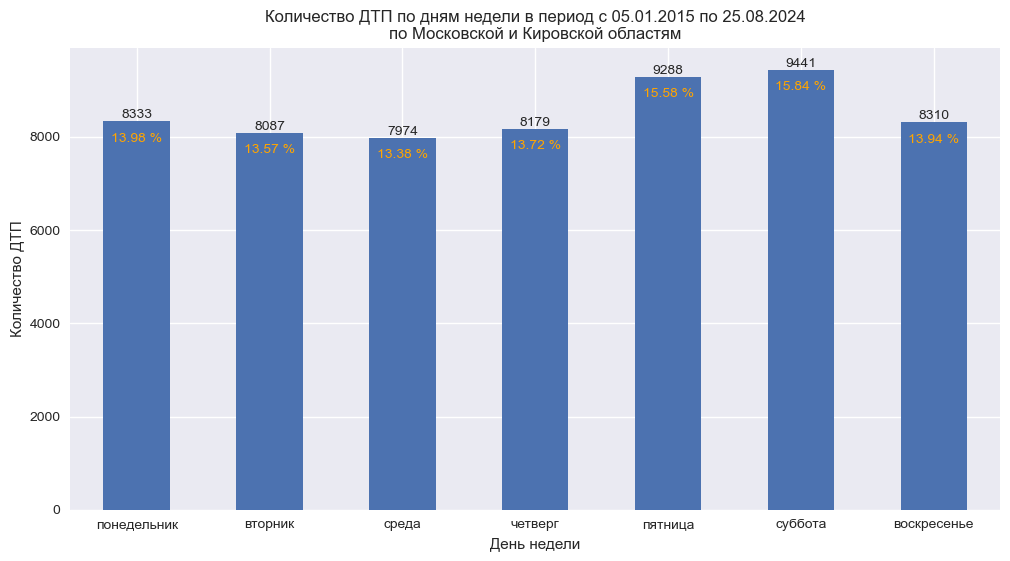

In [164]:
plt.style.use('seaborn-v0_8')

fig, ax = plt.subplots(figsize = (12, 6))

ax = week_info['total'].plot(kind='bar',
                             rot=0,
                             title='Количество ДТП по дням недели в период с 05.01.2015 по 25.08.2024\nпо Московской и Кировской областям',
                            )

ax.set_xticks(week_info.index, ['понедельник',
                                'вторник',
                                'среда',
                                'четверг',
                                'пятница',
                                'суббота',
                                'воскресенье'])

for xi, yi, text in zip(week_info.index, week_info['total'].tolist(), week_info['total'].tolist()):
    ax.text(xi, yi, text, ha='center', va='bottom')

for xi, yi, text in zip(week_info.index, week_info['total'].tolist(), week_info['share'].tolist()):
    ax.text(xi, yi-500, f'{round(text * 100, 2)} %', ha='center', va='bottom', color='orange', fontsize=10)

ax.set_xlabel('День недели')
ax.set_ylabel('Количество ДТП')

plt.show()

Днями недели с наибольшим количеством зарегистрированных ДТП являлются пятница и суббота в эти дни произощло (15,58 % и 15,84 % ДТП соответственно). Наименьшей аварийностью отметичиль вторник (13,57 % ДТП) и среда (13,38 %). Аварии в будние дни происходят заметно реже. Наибольший риск ДТП возникает в конце рабочей недели и начале выходных. При этом наибольшее количество ДТП в субботу контринтуитивно. Есть предположение, что снижение потока машин, характерное для выходных дней ведет к увеличению аварийности на дорогах. Большая доля ДТП в пятницу и субботу может быть связана с увеличением доли нетрезвых водителей.

**Распредение ДТП по месяцам**

Так как важно учитывать статистику по целым годам, отфильтруем данные за период с сентября 2015 года по август 2024 года.

Оставим только поля с идентификаторами ДТП и временем их регистрации.

In [165]:
month_info = df[['id', 'datetime']]
month_info = month_info[(month_info['datetime'] > '2015-09-01') & (month_info['datetime'] < '2024-09-01')]
print(f'Дата начала периода {month_info['datetime'].min()}, дата окончания периода - {month_info['datetime'].max()}')
print(f'Исключено {df.shape[0] - month_info.shape[0]} ДТП')
month_info.head()

Дата начала периода 2015-09-01 00:20:00, дата окончания периода - 2024-08-31 22:50:00
Исключено 5444 ДТП


,id,datetime
0,2163589,2019-01-31 09:05:00
1,2155398,2018-09-22 05:00:00
2,2163319,2019-01-24 19:30:00
3,2143938,2018-01-25 16:00:00
4,2163390,2019-01-14 17:40:00


In [166]:
# Создаем колонку с месяцем ДТП
month_info['month'] = month_info['datetime'].dt.month
month_info.head()

,id,datetime,month
0,2163589,2019-01-31 09:05:00,1
1,2155398,2018-09-22 05:00:00,9
2,2163319,2019-01-24 19:30:00,1
3,2143938,2018-01-25 16:00:00,1
4,2163390,2019-01-14 17:40:00,1


In [167]:
# Группируем данные по месяцу и считаем количество ДТП
month_agg = month_info.groupby('month', as_index=False)['id'].count()

# Считаем долю ДТП по месяцам
month_agg['share'] = month_agg.id / month_agg.id.sum()

month_agg

,month,id,share
0,1,3790,0.069316
1,2,3097,0.056642
2,3,3206,0.058635
3,4,3488,0.063793
4,5,4440,0.081204
5,6,4978,0.091044
6,7,5290,0.096750
7,8,5608,0.102566
8,9,5625,0.102877
9,10,5444,0.099567


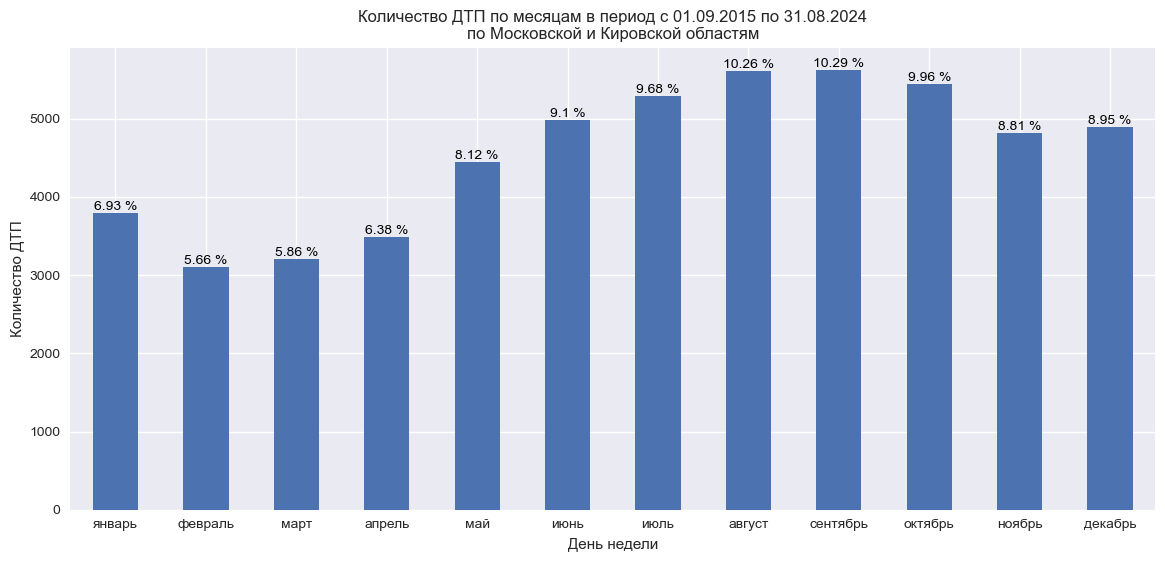

In [168]:
fig, ax = plt.subplots(figsize = (14, 6))

ax = month_agg['id'].plot(kind='bar',
                             rot=0,
                             title='Количество ДТП по месяцам в период с 01.09.2015 по 31.08.2024\nпо Московской и Кировской областям',
                            )

ax.set_xticks(month_agg.index, ['январь',
                                'февраль',
                                'март',
                                'апрель',
                                'май',
                                'июнь',
                                'июль',
                                'август',
                                'сентябрь',
                                'октябрь',
                                'ноябрь',
                                'декабрь'
                               ])

for xi, yi, text in zip(month_agg.index, month_agg.id, month_agg.share):
    ax.text(xi, yi, f'{round(text * 100, 2)} %', ha='center', va='bottom', color='black', fontsize=10)

ax.set_xlabel('День недели')
ax.set_ylabel('Количество ДТП')

plt.show()

In [169]:
month_agg.transpose()

,0,1,2,3,4,5,6,7,8,9,10,11
month,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.00000,8.000000,9.000000,10.000000,11.000000,12.000000
id,3790.000000,3097.000000,3206.000000,3488.000000,4440.000000,4978.000000,5290.00000,5608.000000,5625.000000,5444.000000,4817.000000,4894.000000
share,0.069316,0.056642,0.058635,0.063793,0.081204,0.091044,0.09675,0.102566,0.102877,0.099567,0.088099,0.089507


Прослеживается фактор сезонности: большинство ДТП приходится на теплое время года. Так наибольшее количество аварий проишло в августе и сентябре (10,26 % и 10,29 %), а наименьшее в феврале и марте (5,66 % и 5,86 %). Предполагается, что тяжелые дорожные условия (гололед, слякоть и тому подобное) не являются главным фактором повышенной аварийности. Также снижение аварийности в зимние месяцы может быть связано с общим снижением количества транспорта на дорогах. Следует собрать данные по количеству автотранспорта в разные сезоны.

### 3.2. Анализ ДТП в разрезе стажа водителей

In [170]:
# Отберем строки датасета с информацией об участниках, касающихся только водителей
drivers = df_part[df_part.role == 'Водитель']
drivers

,role,violations,health,driving_exp,id,is_male
0,Водитель,(),Не пострадал,13,2163589,True
2,Водитель,"(Неправильный выбор дистанции,)",Не пострадал,5,2155398,True
4,Водитель,(),Не пострадал,11,2163319,False
5,Водитель,"(Несоблюдение очередности проезда перекрестков,)",Не пострадал,23,2143938,True
7,Водитель,(),Не пострадал,19,2163390,True
...,...,...,...,...,...,...
124110,Водитель,(Несоответствие скорости конкретным условиям д...,Не пострадал,0,2553530,<NA>
124397,Водитель,(Невыполнение требований обеспечения безопасно...,Не пострадал,0,2524279,<NA>
126301,Водитель,"(Несоблюдение условий, разрешающих движение тр...",Не пострадал,0,1983331,<NA>
126315,Водитель,(Несоответствие скорости конкретным условиям д...,Не пострадал,0,2524260,<NA>


In [171]:
# Подсчитаем количество ДТП в разрезе водительского стража
drivers_agg = drivers.groupby('driving_exp', as_index=False)['id'].count()
drivers_agg['procent'] = round(100 * drivers_agg.id / drivers_agg.id.sum(), 2)
drivers_agg

,driving_exp,id,procent
0,0,4686,9.19
1,1,2096,4.11
2,2,1746,3.42
3,3,1834,3.60
4,4,1781,3.49
...,...,...,...
64,64,3,0.01
65,65,3,0.01
66,66,2,0.00
67,67,1,0.00


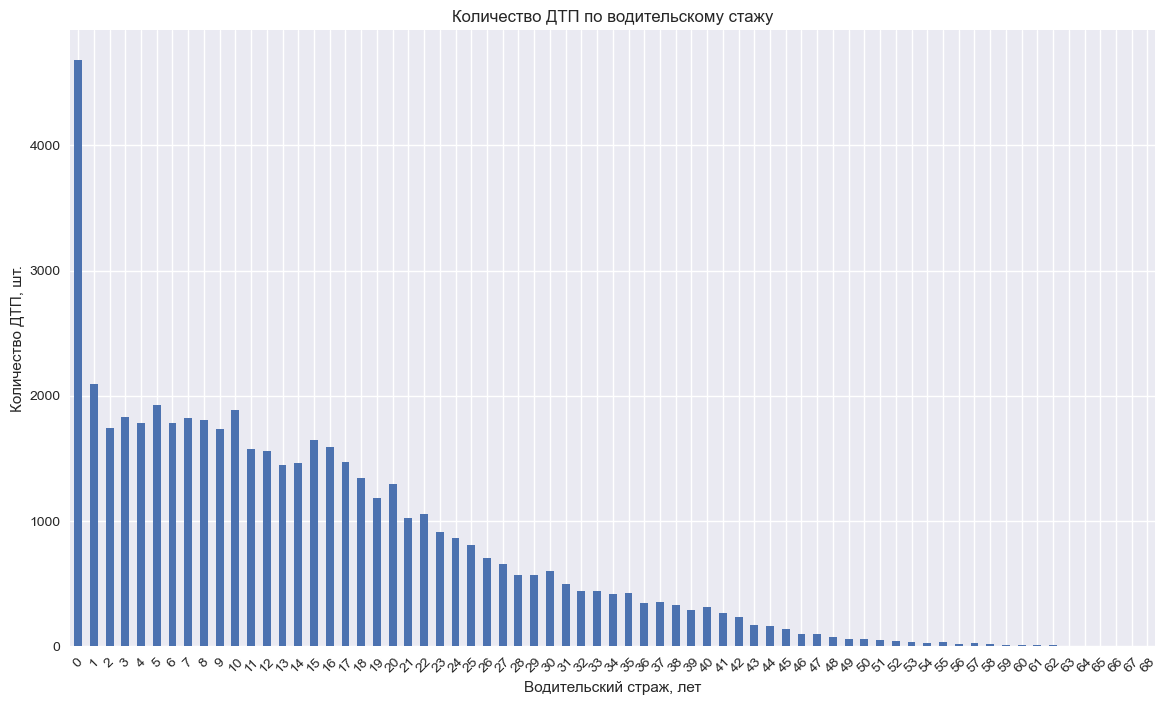

In [172]:
# Построим график распределения количества ДТП в зависимости от стажа водителя

fig, ax = plt.subplots(figsize=(14, 8))

ax = drivers_agg['id'].plot(kind='bar', rot=45, title='Количество ДТП по водительскому стажу')

ax.set_xlabel('Водительский страж, лет')
ax.set_ylabel('Количество ДТП, шт.')

plt.show()

Прослеживается отрицательная корреляция между величиной водительского стажа и количетвом ДТП в каждой категории водительского стажа. При этом можно проследить пики количества зарегистрированных ДТП на стаже, кратном 5 (5, 10, 15, 20, 25 и тд.), данные искажения должны быть связаны с регистрацией некоторых ДТП без детализации водительского стража, следует пересмотреть особенности сбора данных, так как эти условные округления могут вносить искажения в данных. Для дальнейших исследований рассмотреть возможность группировки данных в интервале водительского стажа, кратного 5 для снижения искажений.

Дополнительно обращаем внимание на то, что данные содержат аномальные значения, связанные с тем, что зарегистрированные ДТП с водителем с пропущенным водительским стажем условно заполнены водительским стажем 0. Для дальнейшего анализа данные следует очистить от этого вброса. Дополнительно отметит, что водитель без стажа наиболее опасен в разрезе всех категорий водительского стажа, так как в этой группе зарегистрировано наибольшее число ДТП - 4686, что составляет 9.19 % от всех ДТП.

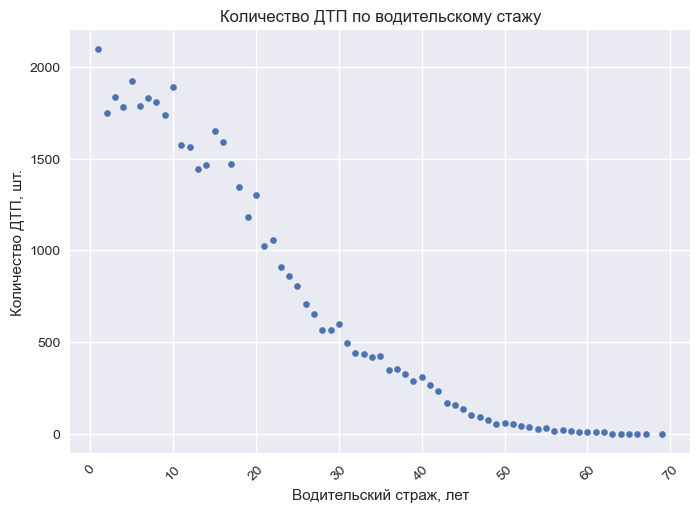

In [173]:


ax = drivers_agg.iloc[1:].plot(kind='scatter', # Исключаем первую строчку с нулевым водительским стажем
                      x='driving_exp',
                      y='id',
                      rot=45, 
                      title='Количество ДТП по водительскому стажу')

ax.set_xlabel('Водительский страж, лет')
ax.set_ylabel('Количество ДТП, шт.')

plt.show()

In [174]:
drivers_agg.iloc[1:][['driving_exp', 'id']].corr() # Коэффициент коррелиции величины водительского стажа и количества ДТП

,driving_exp,id
driving_exp,1.000000,-0.946664
id,-0.946664,1.000000


Меньшее количество ДТП характерно для участников со значительным водительским стажем.

Так как данные содержат выбросы по диапазонам в 5 лет, категоризацию проведем по следующим диапазонам
- до 5 лет (включительно)
- до 10 лет (включительно)
- до 15 лет (включительно)
- до 20 лет (включительно)
- до 25 лет (включительно)
- до 30 лет (включительно)
- до 35 лет (включительно)
- свыше 35 лет

In [175]:
def get_category(row):
    """ 
    Категоризирует водитеский стаж
    Если водительский стаж равен 0 не возвращает ничего
    """
    if row.driving_exp > 35:
        return 'свыше 35 лет'
    elif row.driving_exp > 30:
        return 'до 35 лет'
    elif row.driving_exp > 25 :
        return 'до 30 лет'
    elif row.driving_exp > 20:
        return 'до 25 лет'
    elif row.driving_exp > 15:
        return 'до 20 лет'
    elif row.driving_exp > 10:
        return 'до 15 лет'
    elif row.driving_exp > 5:
        return 'до 10 лет'
    elif row.driving_exp > 0:
        return 'до 5 лет'

In [176]:
# Созданим колонку с категорией водительского стажа
drivers_agg['exp_category'] = drivers_agg.apply(get_category, axis=1)
drivers_agg

,driving_exp,id,procent,exp_category
0,0,4686,9.19,None
1,1,2096,4.11,до 5 лет
2,2,1746,3.42,до 5 лет
3,3,1834,3.60,до 5 лет
4,4,1781,3.49,до 5 лет
...,...,...,...,...
64,64,3,0.01,свыше 35 лет
65,65,3,0.01,свыше 35 лет
66,66,2,0.00,свыше 35 лет
67,67,1,0.00,свыше 35 лет


In [177]:
# Выполним группировку по категории водительского стажа и подсчитаем общее количество ДТП внутри категории
category_stats = drivers_agg.groupby('exp_category', as_index=False)['id'].sum()
category_stats

,exp_category,id
0,до 10 лет,9047
1,до 15 лет,7693
2,до 20 лет,6884
3,до 25 лет,4657
4,до 30 лет,3097
5,до 35 лет,2224
6,до 5 лет,9381
7,свыше 35 лет,3312


In [178]:
# Так как категориальные данные являются ординарными составим словарь, для расположения их по порядку
category_order = {'до 5 лет': 1,
                  'до 10 лет': 2,
                  'до 15 лет': 3,
                  'до 20 лет': 4,
                  'до 25 лет': 5,
                  'до 30 лет': 6,
                  'до 35 лет': 7,
                  'свыше 35 лет': 8
                 }

def get_exp_category_number(row):
    """ Находит порядковый номер категории """
    return category_order[row.exp_category]

category_stats.index = category_stats.apply(get_exp_category_number, axis=1) # Меняем индексы на порядковый номер категории

category_stats = category_stats.sort_index() # Сортируем данные по возрастанию индекса

category_stats['percent'] = round(100 * category_stats.id / category_stats.id.sum(), 2) # Процент от общего числа ДТП для категории

category_stats

,exp_category,id,percent
1,до 5 лет,9381,20.26
2,до 10 лет,9047,19.54
3,до 15 лет,7693,16.62
4,до 20 лет,6884,14.87
5,до 25 лет,4657,10.06
6,до 30 лет,3097,6.69
7,до 35 лет,2224,4.80
8,свыше 35 лет,3312,7.15


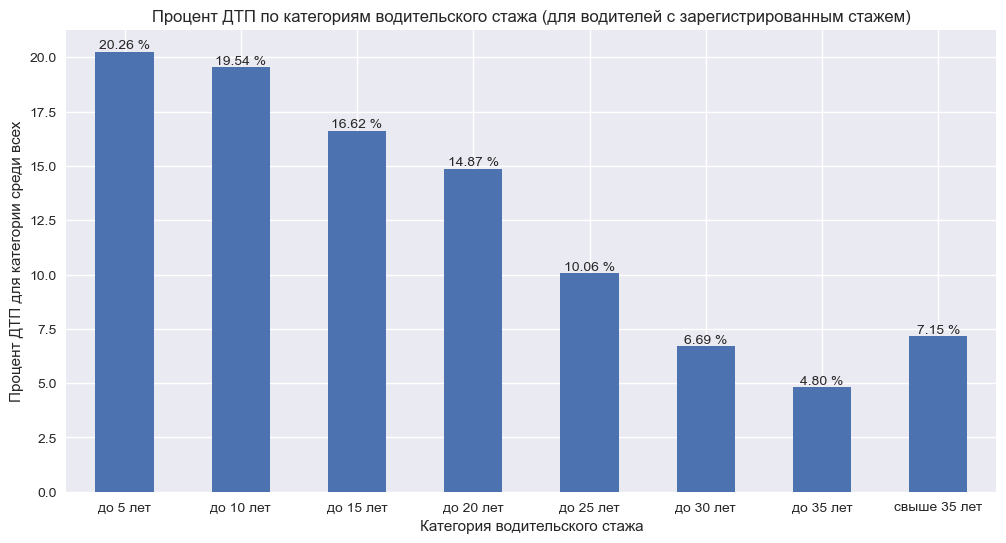

In [179]:
fig, ax = plt.subplots(figsize=(12, 6))

ax = category_stats['percent'].plot(kind='bar',
                                    rot=0,
                                   title='Процент ДТП по категориям водительского стажа (для водителей с зарегистрированным стажем)')

for xi, yi, text in zip(range(category_stats.shape[0]), category_stats.percent, category_stats.percent):
    ax.text(xi, yi, f'{text:.2f} %', ha='center', va='bottom')

ax.set_xticks(range(category_stats.shape[0]), category_stats.exp_category)
ax.set_xlabel('Категория водительского стажа')
ax.set_ylabel('Процент ДТП для категории среди всех')

plt.show()

Число ДТП для водителей с большим водительским стажем меньше. Можно сделать предположение о том, что высокий водительский стаж участника дорожного движения ведет к снижению его аварийного риска. Для подтвеждения предположения следует рассмотренить возможность дополнительного статистического исследования показателя (разработать регрессионную модель зависимости водительского стажа от количества ДТП).

### 3.3. Анализ количества ДТП по Кировской и Московской областям по годам

Проанализируйте, как менялось число аварий по годам в Кировской и Московской областях. При этом включите город Киров в соответствующую область, а Москву исключите. Также определите, в какой области больше аварий в относительном выражении — в пересчёте на 100 тысяч жителей.

In [180]:
# Так как необходимо анализировать число аварий по годам, а данные за 2024 год представлены не в полном объеме,
# отфильтруем данные по начало 2024 года
df_cln = df[df['datetime'] < '2024-01-01']

# Проверка корректности филтрации данных
df_cln.datetime.max()

Timestamp('2023-12-31 19:48:00')

Из данных по Московской области следует исключить саму Москву, определим, какие именно регионы относятся к Москве.

In [181]:
# Список регионов Московской области
sorted(df_cln.loc[df_cln.is_mo == True]['region'].unique().tolist())

['Балашиха',
 'Бронницы',
 'Власиха',
 'Волоколамский',
 'Воскресенский',
 'Дзержинский',
 'Дмитровский',
 'Долгопрудный',
 'Домодедово',
 'Дубна',
 'Егорьевский',
 'Железнодорожный',
 'Жуковский',
 'Зарайский',
 'Звенигород',
 'Ивантеевка',
 'Истринский',
 'Каширский',
 'Климовск',
 'Клинский',
 'Коломенский',
 'Коломна',
 'Королёв',
 'Котельники',
 'Красноармейск',
 'Красногорский',
 'Ленинский',
 'Лобня',
 'Лосино-Петровский',
 'Лотошинский',
 'Луховицкий',
 'Лыткарино',
 'Люберецкий',
 'Можайский',
 'Мытищинский',
 'Наро-Фоминский',
 'Ногинский',
 'Одинцовский',
 'Озёрский',
 'Орехово-Зуево',
 'Орехово-Зуевский',
 'Павлово-Посадский',
 'Подольск',
 'Подольский',
 'Протвино',
 'Пушкинский',
 'Пущино',
 'Раменский',
 'Реутов',
 'Рошаль',
 'Рузский',
 'Сергиево-Посадский',
 'Серебряно-Прудский',
 'Серпухов',
 'Серпуховский',
 'Солнечногорский',
 'Ступинский',
 'Талдомский',
 'Фрязино',
 'Химки',
 'Чеховский',
 'Шатурский',
 'Шаховской',
 'Щелковский',
 'Электросталь']

По списку написан промт для нейросети Алиса AI следующего содержания
определи для регионов из списка
['Балашиха',
 'Бронницы',
 'Власиха',
 'Волоколамский',
 'Воскресенский',
 'Дзержинский',
 'Дмитровский',
 'Долгопрудный',
 'Домодедово',
 'Дубна',
 'Егорьевский',
 'Железнодорожный',
 'Жуковский',
 'Зарайский',
 'Звенигород',
 'Ивантеевка',
 'Истринский',
 'Каширский',
 'Климовск',
 'Клинский',
 'Коломенский',
 'Коломна',
 'Королёв',
 'Котельники',
 'Красноармейск',
 'Красногорский',
 'Ленинский',
 'Лобня',
 'Лосино-Петровский',
 'Лотошинский',
 'Луховицкий',
 'Лыткарино',
 'Люберецкий',
 'Можайский',
 'Мытищинский',
 'Наро-Фоминский',
 'Ногинский',
 'Одинцовский',
 'Озёрский',
 'Орехово-Зуево',
 'Орехово-Зуевский',
 'Павлово-Посадский',
 'Подольск',
 'Подольский',
 'Протвино',
 'Пушкинский',
 'Пущино',
 'Раменский',
 'Реутов',
 'Рошаль',
 'Рузский',
 'Сергиево-Посадский',
 'Серебряно-Прудский',
 'Серпухов',
 'Серпуховский',
 'Солнечногорский',
 'Ступинский',
 'Талдомский',
 'Фрязино',
 'Химки',
 'Чеховский',
 'Шатурский',
 'Шаховской',
 'Щелковский',
 'Электросталь']
Относятся ли они к г. Москва

Ответ дай в формате словаря python, где True - относится, False - не относится

Результат выполнения промта:

Все перечисленные населённые пункты и районы относятся к Московской области, а не к городу Москве.

{
    'Балашиха': False,
    'Бронницы': False,
    'Власиха': False,
    'Волоколамский': False,
    'Воскресенский': False,
    'Дзержинский': False,
    'Дмитровский': False,
    'Долгопрудный': False,
    'Домодедово': False,
    'Дубна': False,
    'Егорьевский': False,
    'Железнодорожный': False,
    'Жуковский': False,
    'Зарайский': False,
    'Звенигород': False,
    'Ивантеевка': False,
    'Истринский': False,
    'Каширский': False,
    'Климовск': False,
    'Клинский': False,
    'Коломенский': False,
    'Коломна': False,
    'Королёв': False,
    'Котельники': False,
    'Красноармейск': False,
    'Красногорский': False,
    'Ленинский': False,
    'Лобня': False,
    'Лосино-Петровский': False,
    'Лотошинский': False,
    'Луховицкий': False,
    'Лыткарино': False,
    'Люберецкий': False,
    'Можайский': False,
    'Мытищинский': False,
    'Наро-Фоминский': False,
    'Ногинский': False,
    'Одинцовский': False,
    'Озёрский': False,
    'Орехово-Зуево': False,
    'Орехово-Зуевский': False,
    'Павлово-Посадский': False,
    'Подольск': False,
    'Подольский': False,
    'Протвино': False,
    'Пушкинский': False,
    'Пущино': False,
    'Раменский': False,
    'Реутов': False,
    'Рошаль': False,
    'Рузский': False,
    'Сергиево-Посадский': False,
    'Серебряно-Прудский': False,
    'Серпухов': False,
    'Серпуховский': False,
    'Солнечногорский': False,
    'Ступинский': False,
    'Талдомский': False,
    'Фрязино': False,
    'Химки': False,
    'Чеховский': False,
    'Шатурский': False,
    'Шаховской': False,
    'Щелковский': False,
    'Электросталь': False
}


Вся информация о ДТП по Московской области представлена для области за исключением Москвы. Дополнительная обработка данных не требуется.

In [182]:
# Проверим данные по ДТП по Кировской области, выведя все представленные регионы
sorted(df_cln[df_cln.is_mo == False]['region'].unique().tolist())

['Арбажский район',
 'Афанасьевский район',
 'Белохолуницкий район',
 'Богородский район',
 'Верхнекамский район',
 'Верхошижемский район',
 'Вятско-Полянский район',
 'Даровской район',
 'Зуевский район',
 'Кикнурский район',
 'Кильмезский район',
 'Киров',
 'Кирово-Чепецки район',
 'Котельничский район',
 'Куменский район',
 'Лебяжский район',
 'Лузский район',
 'Малмыжский район',
 'Мурашинский район',
 'Нагорский район',
 'Немский район',
 'Нолинский район',
 'Омутнинский район',
 'Опаринскийрайон',
 'Оричевский район',
 'Орловский район',
 'Пижанский район',
 'Подосиновский район',
 'Санчурский район',
 'Свечинский район',
 'Слободской район',
 'Советский район',
 'Сунский район',
 'Тужинский район',
 'Унинский район',
 'Уржумский район',
 'Фаленский район',
 'Шабалинский район',
 'Юрьянский район',
 'Яранский район']

Поскольку город Киров включен в список регионов, дополнительной обработки данных не требуется. Условие о том, что данные должны быть представлены по Московской области, исключая Москву, и по Кироской области, включая Киров, выполняются. Данные дополнительной фильтрации по региональному признаку.

Данные по населению Московской и Кировской области были получены с сайтов соответствующих управлений Федеральной службы государственной статистики. Список источников:

1. http://statkirov.43.rosstat.gov.ru/dg/dg6/dbinet.cgi - Данные по населению Кировской области
2. https://77.rosstat.gov.ru/Статистика/Официальная_статистика/Московская_область/Население# - Данные по населения Московской области

Данные собраны в файле `population1000.csv`. Датасет содержит 3 поля:
- `year` - год, на 1 января которого представлены данные по численности населения
- `population` - количество населения в тыс. человек
- `is_mo` - признак того, относятся ли данные к Московской области (True - данные по Московской области, False - данные по Кировской области)

In [183]:
# Загружаем данные по численности населения
population = pd.read_csv('population1000.csv')
population

,year,population,is+AF8-mo
0,2015,1271,False
1,2016,1257,False
2,2017,1244,False
3,2018,1228,False
4,2019,1210,False
5,2020,1193,False
6,2021,1173,False
7,2022,1149,False
8,2023,1138,False
9,2015,7231,True


In [184]:
population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        18 non-null     int64
 1   population  18 non-null     int64
 2   is+AF8-mo   18 non-null     bool 
dtypes: bool(1), int64(2)
memory usage: 438.0 bytes


In [185]:
# Меняем название столбца на is_mo, так как имеется проблема с кодировкой
population = population.rename(columns={'is+AF8-mo': 'is_mo'})

# Понижаем разрядность числовых типов данных
columns = ['year', 'population']
for column in columns:
    population[column] = pd.to_numeric(population[column], downcast='integer')

population.info() # Проверка корретности преобразований

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        18 non-null     int16
 1   population  18 non-null     int16
 2   is_mo       18 non-null     bool 
dtypes: bool(1), int16(2)
memory usage: 222.0 bytes


In [186]:
# Загрузим только необходимые для отвена на исследовательских вопрос данные в переменную
loc_info = df_cln[['id', 'datetime', 'is_mo']]

# Определим год для каждого зарегистрированного ДТП
loc_info['year'] = loc_info['datetime'].dt.year

# Удаляем ненежную колонку datetime
loc_info = loc_info.drop('datetime', axis=1)

loc_info.head()

C:\Users\Гибарян\AppData\Local\Temp\ipykernel_11640\3437566356.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  loc_info['year'] = loc_info['datetime'].dt.year


,id,is_mo,year
0,2163589,True,2019
1,2155398,True,2018
2,2163319,True,2019
3,2143938,True,2018
4,2163390,True,2019


In [187]:
# Cчитаем количесво ДТП для каждого региона и каждого года
loc_agg = loc_info.groupby(['year', 'is_mo'], as_index=False)['id'].count()

loc_agg.head()

,year,is_mo,id
0,2015,False,1523
1,2015,True,6643
2,2016,False,1465
3,2016,True,5794
4,2017,False,1450


In [188]:
# Объединяем подсчет количества ДТП по годам с данными по численности населения
loc_agg = loc_agg.merge(population, on=['year', 'is_mo'], how='left')

# Считаем количество ДТП на 100 тыс. населения
loc_agg['per_population'] = loc_agg.id / loc_agg.population * 100

loc_agg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            18 non-null     int32  
 1   is_mo           18 non-null     bool   
 2   id              18 non-null     int64  
 3   population      18 non-null     int16  
 4   per_population  18 non-null     float64
dtypes: bool(1), float64(1), int16(1), int32(1), int64(1)
memory usage: 546.0 bytes


In [189]:
# Установим год в качестве индекса
loc_agg = loc_agg.set_index(loc_agg.year)

loc_agg.head()

,year,is_mo,id,population,per_population
year,,,,,
2015,2015,False,1523,1271,119.826908
2015,2015,True,6643,7231,91.868345
2016,2016,False,1465,1257,116.547335
2016,2016,True,5794,7319,79.163820
2017,2017,False,1450,1244,116.559486


In [190]:
# Собирем датасет, где для каждой области имеется отдельная колонка с данными по количеству ДТП на 100 тыс. человек
per_1000 = pd.DataFrame({'Московская область': loc_agg.loc[loc_agg.is_mo == True]['per_population'],
                         'Кировская область': loc_agg.loc[loc_agg.is_mo == False]['per_population']
                        })

per_1000

,Московская область,Кировская область
year,,
2015,91.868345,119.826908
2016,79.163820,116.547335
2017,77.421528,116.559486
2018,67.999467,131.270358
2019,67.250000,129.586777
2020,54.817319,125.565801
2021,50.570835,129.923274
2022,39.253102,120.626632
2023,39.245810,130.579965


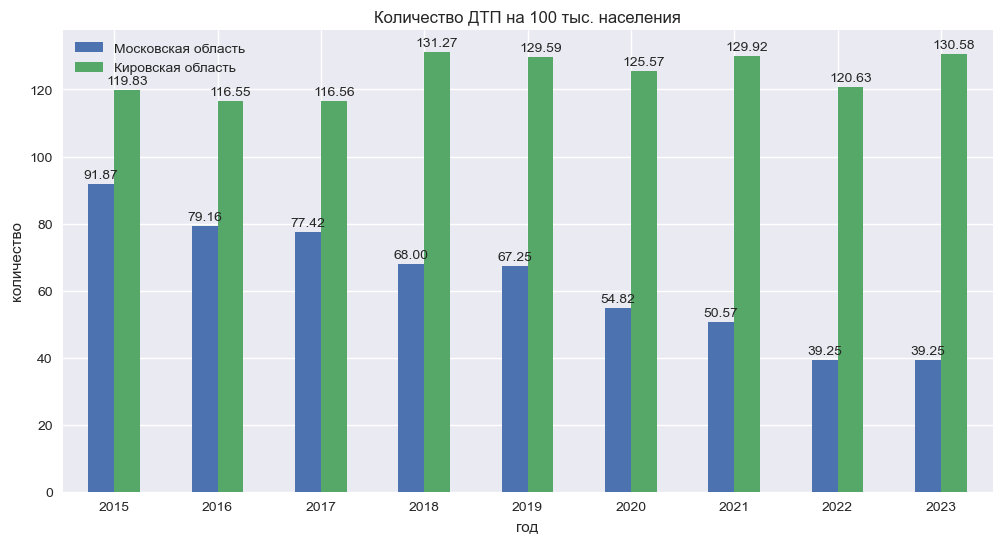

In [191]:
ax = per_1000.plot(kind='bar',
             rot=0,
             figsize=(12, 6)
             )

plt.title('Количество ДТП на 100 тыс. населения')
plt.xlabel('год')
plt.ylabel('количество')

# Добавляем подписи к столбцам
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2)  # fmt — формат числа, padding — отступ


plt.show()

Количество ДТП в год по Московской области в период с 2015 по 2023  годы неуклонно снижалось. В это же время количество ДТП по Кировской области в пересчена на 100 тыс. населения незначительно увиличивалось. Увеличение разрыва в безопасности дорог двух исследуемых регионах может быть связано с опережающим развитием дорожной инфраструктуры в Московской области относительно Кировской. К началу исследуемого периода показатели различались на 20 процентов, а в 2023 году показатели стали различаться более чем в 3 раза. Для повышения безопасности на дорогах особое внимание следует уделить дорожной инфраструктуре провинциальных регионов.

## 4. Выводы

По результатам работы проведена предобработка данных, представленных в 6 датасетах заказчиком. Данные по однородным датасетам объединены в один так, что получилось 3 датасета готовых для дальнейшей работы:
- `df` - датасет с общей информацией по ДТП. Из названией колонок исключены названия схем базы данных. Для датасета отредактированы географические координаты аварий так, что оставлены только две колонки с данными по широте и долготе ДТП. При этом пропущенные координаты заполнены вручную через поиск данных в интернете, а там где они были указаны некорретно - строки удалены. Информация о субъекте заменена на колонку булева типа `is_mo`, означающую, относится ли ДТП к Московской области (если нет - то оно произошло в Кировской области). Данные в спископодобных колонках приведены к типу кортежей, отортитовары по алфавиту для исключения перестановок, и стали более доступны для последующей работы путем обращения по индексу к контретным значениям внутри этих кортежей. Типы данных оптимизированы с целью экономии памями (у числовых понижена разрядность, у категориальных - изменен тип). Для времени ДТП установлен тип данных дата и время. Значения по полю `adress` нормализованы путем приведения их к заглавному регистру.
- `df_part` - датасет с информацией по участникам ДТП. Данные по областям объединены в один датасет. Для дальнейшего анализа предлагается выполнять их разделение на основе данных из `df`. Обнаружены дубликаты в записях участников ДТП по Московской области, эти дубликаты исключены. Пропуски в данных заполнены техническими значениями, за исключением колонки `gender`, в ней данные пропуски оставлены без изменения, а сама колонка заменена на поле `is_male` булева типа. Значение True по этому полю означает, что участник мужского пола, значение False - участник женского пола, пропуск - информация отсутствует. Нарушения в "спископодобном" виде зменены на кортежи с исключенными перестановками. Переименованые длинные наименовая колонок. Оптимизированы типы данных.
- `df_vech` - датасет с информацией по транспортным средствам. Два датасета объединены в один, разделение по областям следует проводить на основе индентификаторов ДТП и данных из `df`. Исключены ошибки в написании пробелов по текстовым полям. Все текстовые поля нормализованы путем перевода в заглавный регистр, за исключением цвета авто и его категории. Удалены явные дубликаты из датасета. Пропущенные значения заполненны техническим `no_info`. Типы данных оптимизированы с целью экономии памяти.

Также были представлены ответы на аналитические вопросы, поставленные заказиком:
- Определено распределение числа ДТП по временным промежуткам (по дням недели и по месяцам)
- Выявлена взаимосвять водительского опыта и количества ДТП.
- Определено различие годового количиества ДТП в двух исследуемых областях (Московской и Кировской)

Рекомендуется оптимизировать сбор данных путем исключения дублирования информации по географическим координатам места ДТП (оставить либо две колонки с широтой и долготой, либо одну - с координатами в форме кортежа). Усилить контроль за полнотой сбора информации по адресу места ДТП, так как по колонке имеется достаточно большое количество пропусков. Данные по разным регионам можно объединить в одной таблице в базе данных, добавив дополительный атрибут с номером региона (как на государственных номерах автотранспортных средств). Данные оформленные в виде списка следует собирать с сортировкой, для того, чтобы исключить перестановки.

Исследование данные позволило выявить рост количества ДТП в период конца рабочей недели. Необходимо провести статистическую проверку данного предположения. Если это явление найдет подтверждение, заказчику рекомендуется принять меры по усилению безопасности на дорогах в преод с пятницы по понедельник. Также на основе данных обнаружено, что количество ДТП в теплое время года выше относительно холодного времени года. Необходимо выястнить, с чем связано такая, казалось бы, парадоксальная разница: с уменьшение количества транспорта на дорогах или с изменением водительских привычек в зимнее время.

Следует построить регрессию водительского стажа и количества ДТП. Если предположение о том, что больший водительский стаж ведет к меньшему риску ДТП подтвердится, следует рекомендовать к найму в качестве водителей для автотранспортных предприятий лиц с большим водительским стажем.

Данные отражают увеличивающийся разрыв в бепасности на дорогох окраин относительно центра. Если проверка данного предположения подтвердится, рекомендуется направить дополнительные усилия на повышение безопасности на дорогах провинциальных регионов.